In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

In [3]:
INPUT_ROOT = "/kaggle/input"

for root, dirs, files in os.walk(INPUT_ROOT):
    depth = root.replace(INPUT_ROOT, "").count(os.sep)
    if depth <= 2:
        print(f"{root}  |  {len(dirs)} dirs, {len(files)} files")
        for f in files[:5]:
            print("    ", f)
            

/kaggle/input  |  1 dirs, 0 files
/kaggle/input/competitions  |  1 dirs, 0 files
/kaggle/input/competitions/shl-hiring-assessment-2026  |  1 dirs, 0 files


In [4]:
def find_file(name, root=INPUT_ROOT):
    """Return the first path matching a file name under root."""
    for r, _, files in os.walk(root):
        if name in files:
            return os.path.join(r, name)
    raise FileNotFoundError(name)

TRAIN_CSV  = find_file("train.csv")
TEST_CSV   = find_file("test.csv")
SAMPLE_CSV = find_file("sample_submission.csv")

DATA_DIR = os.path.dirname(TRAIN_CSV)
print("Data dir:", DATA_DIR)
print("Contents:", os.listdir(DATA_DIR))

Data dir: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
Contents: ['sample_submission.csv', 'train.csv', 'test.csv', 'test', 'train']


In [5]:
train_df  = pd.read_csv(TRAIN_CSV)
test_df   = pd.read_csv(TEST_CSV)
sample_df = pd.read_csv(SAMPLE_CSV)

print("train :", train_df.shape)
print("test  :", test_df.shape)
print("sample:", sample_df.shape)

print("\nTrain columns:", list(train_df.columns))
print("Test columns :", list(test_df.columns))
print("Sample cols  :", list(sample_df.columns))

display(train_df.head())
display(test_df.head())
display(sample_df.head())

train : (769, 2)
test  : (216, 2)
sample: (204, 2)

Train columns: ['filename', 'label']
Test columns : ['filename', 'label']
Sample cols  : ['filename', 'label']


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1


,filename,label
0,audio_804.wav,-1
1,audio_1028.wav,-1
2,audio_865.wav,-1
3,audio_774.wav,-1
4,audio_1138.wav,-1


In [6]:
FILE_COL  = train_df.columns[0]   
LABEL_COL = train_df.columns[1]   
print(f"Using FILE_COL='{FILE_COL}', LABEL_COL='{LABEL_COL}'")


wav_paths = {}
for r, _, files in os.walk(INPUT_ROOT):
    for f in files:
        if f.lower().endswith(".wav"):
            wav_paths[f] = os.path.join(r, f)
print("Total .wav files found:", len(wav_paths))

def resolve(fname):
    """Match a CSV file name to a real path, tolerating a missing .wav extension."""
    fname = str(fname)
    if fname in wav_paths:
        return wav_paths[fname]
    if fname + ".wav" in wav_paths:
        return wav_paths[fname + ".wav"]
    return None

train_df["path"] = train_df[FILE_COL].apply(resolve)
test_df["path"]  = test_df[FILE_COL].apply(resolve)

print("Train files missing:", train_df["path"].isna().sum())
print("Test files missing :", test_df["path"].isna().sum())

Using FILE_COL='filename', LABEL_COL='label'
Total .wav files found: 773
Train files missing: 0
Test files missing : 0


In [7]:
print("Duplicate train file names:", train_df[FILE_COL].duplicated().sum())
print("Missing labels:", train_df[LABEL_COL].isna().sum())
print("Label range:", train_df[LABEL_COL].min(), "to", train_df[LABEL_COL].max())
print("Test/train file overlap:", len(set(train_df[FILE_COL]) & set(test_df[FILE_COL])))
print("Test IDs match sample submission:",
      set(test_df[FILE_COL]) == set(sample_df[sample_df.columns[0]]))

print("\nLabel value counts:")
print(train_df[LABEL_COL].value_counts().sort_index())

Duplicate train file names: 0
Missing labels: 0
Label range: 0.0 to 5.0
Test/train file overlap: 212
Test IDs match sample submission: False

Label value counts:
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64


In [8]:
def audio_info(path):
    try:
        i = sf.info(path)
        return pd.Series({"sr": i.samplerate, "channels": i.channels,
                          "duration": i.duration, "subtype": i.subtype, "ok": True})
    except Exception as e:
        return pd.Series({"sr": None, "channels": None, "duration": None,
                          "subtype": None, "ok": False})

train_df = pd.concat([train_df, train_df["path"].apply(audio_info)], axis=1)
test_df  = pd.concat([test_df,  test_df["path"].apply(audio_info)],  axis=1)

for name, d in [("TRAIN", train_df), ("TEST", test_df)]:
    print(f"\n=== {name} ===")
    print("Corrupt files:", (~d["ok"].astype(bool)).sum())
    print("Sample rates :", d["sr"].value_counts().to_dict())
    print("Channels     :", d["channels"].value_counts().to_dict())
    print(d["duration"].describe().round(2))
    


=== TRAIN ===
Corrupt files: 0
Sample rates : {16000: 769}
Channels     : {1: 769}
count    769.00
mean      55.78
std        7.91
min       20.06
25%       54.19
50%       60.07
75%       60.07
max       61.04
Name: duration, dtype: float64

=== TEST ===
Corrupt files: 0
Sample rates : {16000: 216}
Channels     : {1: 216}
count    216.00
mean      49.74
std        8.10
min       23.66
25%       45.06
50%       45.06
75%       60.07
max       61.04
Name: duration, dtype: float64


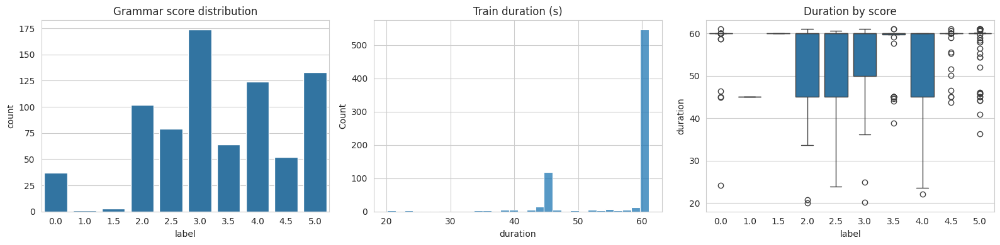

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x=train_df[LABEL_COL], ax=ax[0])
ax[0].set_title("Grammar score distribution")

sns.histplot(train_df["duration"], bins=30, ax=ax[1])
ax[1].set_title("Train duration (s)")

sns.boxplot(x=train_df[LABEL_COL], y=train_df["duration"], ax=ax[2])
ax[2].set_title("Duration by score")

plt.tight_layout()
plt.show()

**EDA**

strat_bin
0     37
2    106
3    253
4    188
5    185
Name: count, dtype: int64

Mean : 3.3134
Std  : 1.2382
Mean-predictor RMSE (floor to beat): 1.2382
Share of variance from label=0 clips: 34.5%


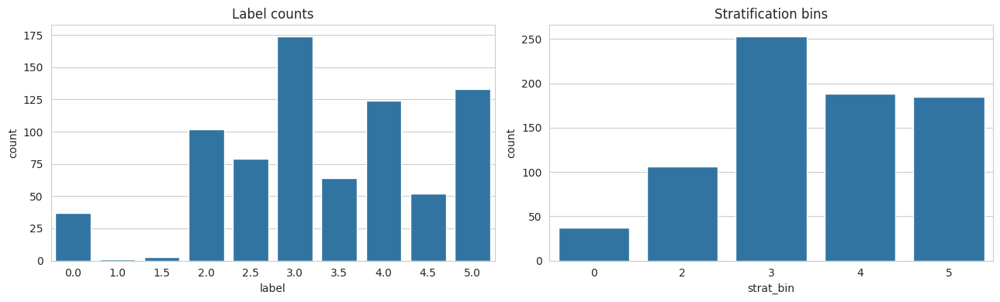

In [10]:
LABEL_COL, FILE_COL = "label", "filename"

def make_bin(x):
    """0 stays alone; 1-2 merged (rare 1 and 1.5); then pairs (2.5-3, 3.5-4, 4.5-5)."""
    if x == 0:   return 0
    if x <= 2:   return 2
    if x <= 3:   return 3
    if x <= 4:   return 4
    return 5

train_df["strat_bin"] = train_df[LABEL_COL].apply(make_bin)
print(train_df["strat_bin"].value_counts().sort_index())

print("\nMean :", round(train_df[LABEL_COL].mean(), 4))
print("Std  :", round(train_df[LABEL_COL].std(ddof=0), 4))
print("Mean-predictor RMSE (floor to beat):",
      round(np.sqrt(((train_df[LABEL_COL] - train_df[LABEL_COL].mean())**2).mean()), 4))

# How much of the total variance comes from the 0-labeled clips?
sse_total = ((train_df[LABEL_COL] - train_df[LABEL_COL].mean())**2).sum()
sse_zero  = ((train_df.loc[train_df[LABEL_COL] == 0, LABEL_COL] - train_df[LABEL_COL].mean())**2).sum()
print(f"Share of variance from label=0 clips: {sse_zero / sse_total:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=train_df[LABEL_COL], ax=ax[0]); ax[0].set_title("Label counts")
sns.countplot(x=train_df["strat_bin"], ax=ax[1]); ax[1].set_title("Stratification bins")
plt.tight_layout(); plt.show()

In [11]:
import librosa, librosa.display
from tqdm.auto import tqdm

def quality_stats(path, sr=16000):
    y, _ = librosa.load(path, sr=sr, mono=True)
    rms = librosa.feature.rms(y=y, frame_length=1024, hop_length=256)[0]
    db = librosa.amplitude_to_db(rms + 1e-9, ref=1.0)
    return {
        "peak": float(np.abs(y).max()),
        "rms_db": float(db.mean()),
        "silence_ratio": float((db < -40).mean()),
        "clip_ratio": float((np.abs(y) > 0.99).mean()),
        "dc_offset": float(y.mean()),
    }

stats = [quality_stats(p) for p in tqdm(train_df["path"])]
q = pd.DataFrame(stats, index=train_df.index)
train_df = pd.concat([train_df.drop(columns=q.columns, errors="ignore"), q], axis=1)

print(train_df[["peak", "rms_db", "silence_ratio", "clip_ratio"]].describe().round(3))

  0%|          | 0/769 [00:00<?, ?it/s]

          peak   rms_db  silence_ratio  clip_ratio
count  769.000  769.000        769.000     769.000
mean     0.753  -38.478          0.390       0.000
std      0.247    8.089          0.171       0.000
min      0.038  -68.724          0.000       0.000
25%      0.638  -43.008          0.300       0.000
50%      0.844  -37.959          0.380       0.000
75%      0.945  -33.943          0.481       0.000
max      1.000  -15.600          0.986       0.001


=== Mean of each metric: label=0 vs label>0 ===
         duration   peak  rms_db  silence_ratio  clip_ratio
is_zero                                                    
False      55.676  0.743 -39.476           0.41         0.0
True       57.864  0.950 -18.745           0.00         0.0

=== Duration clusters (rounded to 0.5 s), top 8 ===
duration
60.1    467
45.1     90
60.0     36
61.0     20
45.0     14
60.2     10
60.6      5
44.1      4
Name: count, dtype: int64

=== Spearman correlation with label (all clips) ===
duration         0.111
peak             0.070
rms_db          -0.091
silence_ratio   -0.055
clip_ratio       0.003
Name: label, dtype: float64

=== Spearman correlation with label (label>0 only) ===
duration         0.142
peak             0.181
rms_db           0.056
silence_ratio   -0.225
clip_ratio      -0.021
Name: label, dtype: float64


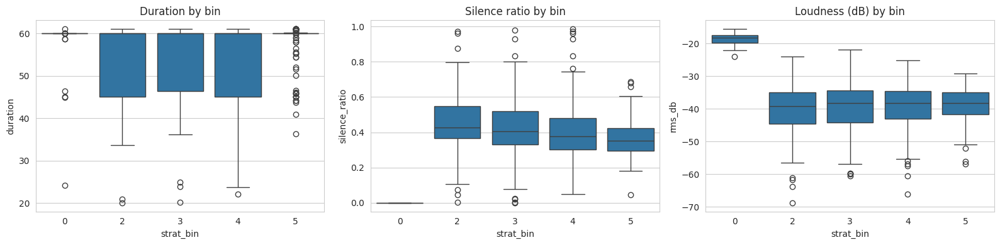

In [12]:
train_df["is_zero"] = (train_df[LABEL_COL] == 0)

cols = ["duration", "peak", "rms_db", "silence_ratio", "clip_ratio"]

print("=== Mean of each metric: label=0 vs label>0 ===")
print(train_df.groupby("is_zero")[cols].mean().round(3))

print("\n=== Duration clusters (rounded to 0.5 s), top 8 ===")
print(train_df["duration"].round(1).value_counts().head(8))

print("\n=== Spearman correlation with label (all clips) ===")
print(train_df[cols + [LABEL_COL]].corr(method="spearman")[LABEL_COL].drop(LABEL_COL).round(3))

print("\n=== Spearman correlation with label (label>0 only) ===")
nz = train_df[~train_df["is_zero"]]
print(nz[cols + [LABEL_COL]].corr(method="spearman")[LABEL_COL].drop(LABEL_COL).round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x="strat_bin", y="duration", data=train_df, ax=ax[0]);      ax[0].set_title("Duration by bin")
sns.boxplot(x="strat_bin", y="silence_ratio", data=train_df, ax=ax[1]); ax[1].set_title("Silence ratio by bin")
sns.boxplot(x="strat_bin", y="rms_db", data=train_df, ax=ax[2]);        ax[2].set_title("Loudness (dB) by bin")
plt.tight_layout(); plt.show()

Label 0.0 | audio_5067.wav | 44.9s | silence=0.00 | rms=-17.6 dB


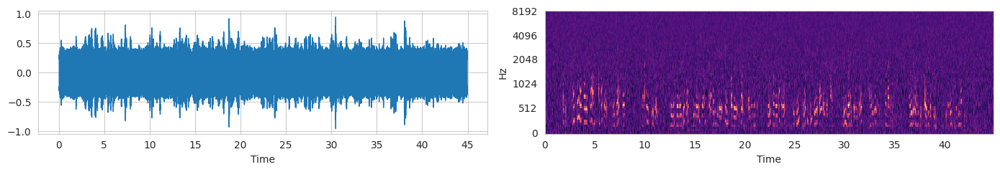

Label 0.0 | audio_5061.wav | 60.1s | silence=0.00 | rms=-17.5 dB


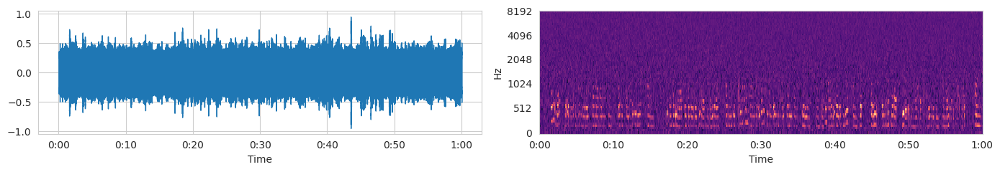

Label 0.0 | audio_5039.wav | 60.1s | silence=0.00 | rms=-24.0 dB


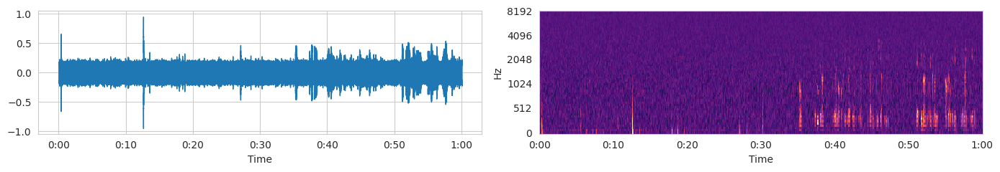

Label 2.0 | audio_86.wav | 45.1s | silence=0.43 | rms=-38.2 dB


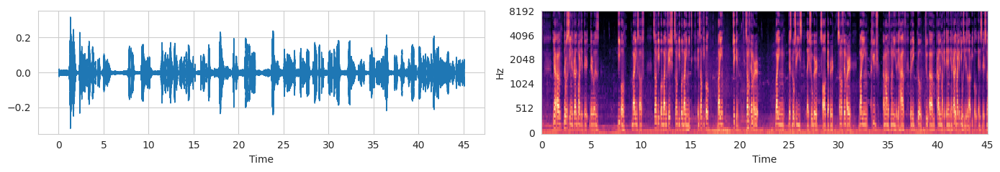

Label 5.0 | audio_240.wav | 60.1s | silence=0.68 | rms=-43.8 dB


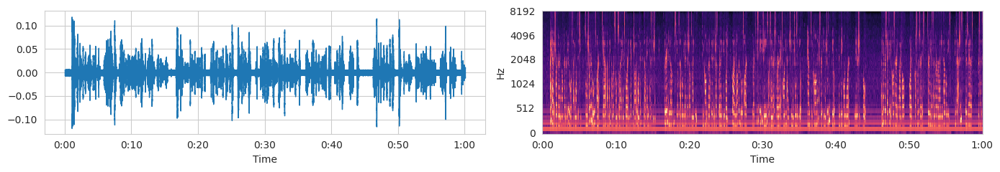

In [13]:
import IPython.display as ipd

zeros = train_df[train_df["is_zero"]].sample(3, random_state=SEED)
others = pd.concat([
    train_df[train_df["strat_bin"] == 2].sample(1, random_state=SEED),
    train_df[train_df["strat_bin"] == 5].sample(1, random_state=SEED),
])

for _, row in pd.concat([zeros, others]).iterrows():
    y, sr = librosa.load(row["path"], sr=16000)
    print(f"Label {row[LABEL_COL]} | {row[FILE_COL]} | {row['duration']:.1f}s | "
          f"silence={row['silence_ratio']:.2f} | rms={row['rms_db']:.1f} dB")
    fig, ax = plt.subplots(1, 2, figsize=(14, 2.5))
    librosa.display.waveshow(y, sr=sr, ax=ax[0])
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="mel", ax=ax[1])
    plt.tight_layout(); plt.show()
    ipd.display(ipd.Audio(y, rate=sr))

From the previous cell I get to know what label 0 actually means, I assumed it to be silent audio but instead it is noise with some speech, so transcriber would catch that speech. 

**AUDIO PREPROCESSING**

In [14]:
import soundfile as sf
import librosa, os
from tqdm.auto import tqdm

SR = 16000
OUT_DIR = "/kaggle/working/audio_16k"
os.makedirs(OUT_DIR, exist_ok=True)

FRAME, HOP, SIL_DB = 1024, 256, -40   # same -40 dB threshold as the earlier silence_ratio

def frame_db(y):
    rms = librosa.feature.rms(y=y, frame_length=FRAME, hop_length=HOP)[0]
    return librosa.amplitude_to_db(rms + 1e-9, ref=1.0)

def pause_features(db):
    """Speech/pause statistics from frame-level energy (computed on RAW audio)."""
    sp = db > SIL_DB
    sec = HOP / SR
    # run-length encode speech/non-speech frames
    change = np.flatnonzero(np.diff(sp.astype(int))) + 1
    runs = np.split(sp, change)
    pauses = [len(r) * sec for r in runs if not r[0]]
    speech = [len(r) * sec for r in runs if r[0]]
    # ignore tiny pauses (<0.2 s) as natural articulation gaps
    long_pauses = [p for p in pauses if p >= 0.2]
    return {
        "speech_ratio": float(sp.mean()),
        "n_speech_segs": len(speech),
        "n_pauses": len(long_pauses),
        "mean_pause": float(np.mean(long_pauses)) if long_pauses else 0.0,
        "max_pause": float(max(long_pauses)) if long_pauses else 0.0,
        "mean_speech_seg": float(np.mean(speech)) if speech else 0.0,
        "pauses_per_min": len(long_pauses) / (len(db) * sec / 60),
    }

def preprocess_one(src_path, fname):
    y, _ = librosa.load(src_path, sr=SR, mono=True)
    db = frame_db(y)
    feats = pause_features(db)

    # light trim: only leading/trailing frames below the silence threshold
    voiced = np.flatnonzero(db > SIL_DB)
    if len(voiced) > 0:
        start = max(voiced[0] * HOP - int(0.1 * SR), 0)          # keep 0.1 s margin
        end = min((voiced[-1] + 1) * HOP + int(0.1 * SR), len(y))
    else:
        start, end = 0, len(y)
    y_t = y[start:end]

    # peak normalize the cached copy
    peak = np.abs(y_t).max()
    if peak > 0:
        y_t = y_t / peak * 0.95

    out_path = os.path.join(OUT_DIR, fname)
    sf.write(out_path, y_t, SR, subtype="PCM_16")

    feats.update({
        "proc_path": out_path,
        "orig_len_s": len(y) / SR,
        "proc_len_s": len(y_t) / SR,
        "trimmed_s": (len(y) - len(y_t)) / SR,
    })
    return feats

In [15]:
all_df = (pd.concat([train_df[["filename", "path"]], test_df[["filename", "path"]]])
            .drop_duplicates("filename").reset_index(drop=True))
print("Unique files to process:", len(all_df))

rows = []
for fn, p in tqdm(zip(all_df["filename"], all_df["path"]), total=len(all_df)):
    d = preprocess_one(p, fn)
    d["filename"] = fn
    rows.append(d)

prep_df = pd.DataFrame(rows)
prep_df.to_csv("/kaggle/working/prep_manifest.csv", index=False)
print(prep_df.describe().round(3).T)

Unique files to process: 773


  0%|          | 0/773 [00:00<?, ?it/s]

                 count    mean     std     min     25%     50%     75%  \
speech_ratio     773.0   0.610   0.172   0.014   0.519   0.620   0.700   
n_speech_segs    773.0  71.159  27.356   1.000  58.000  73.000  88.000   
n_pauses         773.0  22.512   9.008   0.000  18.000  23.000  28.000   
mean_pause       773.0   0.789   0.495   0.000   0.561   0.709   0.925   
max_pause        773.0   3.364   3.519   0.000   1.600   2.384   3.968   
mean_speech_seg  773.0   3.414  12.631   0.063   0.361   0.457   0.584   
pauses_per_min   773.0  24.469  10.171   0.000  19.973  24.185  28.961   
orig_len_s       773.0  55.746   7.917  20.060  53.200  60.075  60.075   
proc_len_s       773.0  52.802   8.600  12.328  45.060  56.952  58.872   
trimmed_s        773.0   2.944   3.687   0.000   0.828   1.944   3.571   

                     max  
speech_ratio       1.000  
n_speech_segs    156.000  
n_pauses          65.000  
mean_pause         5.550  
max_pause         36.208  
mean_speech_seg   61.04

In [16]:
train_df = train_df.drop(columns=[c for c in prep_df.columns if c != "filename" and c in train_df.columns],
                         errors="ignore").merge(prep_df, on="filename", how="left")

print("Missing processed paths:", train_df["proc_path"].isna().sum())
print("Trim seconds, summary:\n", train_df["trimmed_s"].describe().round(2))

# Does trimming ever remove a lot? (flag clips losing > 5 s)
print("Clips losing >5 s:", (train_df["trimmed_s"] > 5).sum())

new_feats = ["speech_ratio", "n_pauses", "mean_pause", "max_pause",
             "mean_speech_seg", "pauses_per_min"]
print("\nSpearman with label (label>0 only):")
nz = train_df[train_df["label"] > 0]
print(nz[new_feats + ["label"]].corr(method="spearman")["label"].drop("label").round(3))

Missing processed paths: 0
Trim seconds, summary:
 count    769.00
mean       2.95
std        3.69
min        0.00
25%        0.83
50%        1.94
75%        3.58
max       36.09
Name: trimmed_s, dtype: float64
Clips losing >5 s: 121

Spearman with label (label>0 only):
speech_ratio       0.225
n_pauses          -0.159
mean_pause        -0.029
max_pause         -0.052
mean_speech_seg    0.129
pauses_per_min    -0.212
Name: label, dtype: float64


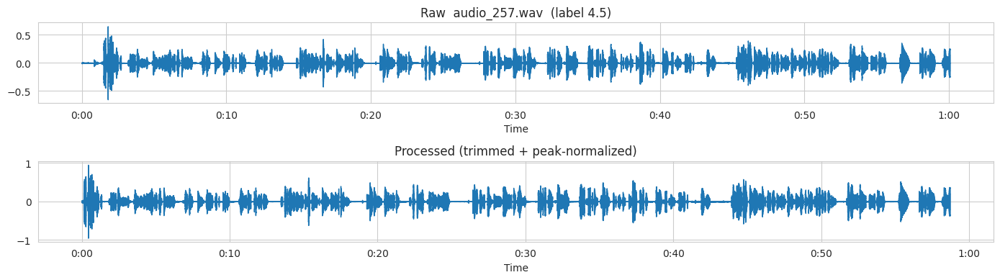

In [17]:
r = train_df[train_df["label"] > 0].sample(1, random_state=SEED).iloc[0]
y0, _ = librosa.load(r["path"], sr=SR)
y1, _ = librosa.load(r["proc_path"], sr=SR)
fig, ax = plt.subplots(2, 1, figsize=(14, 4), sharex=False)
librosa.display.waveshow(y0, sr=SR, ax=ax[0]); ax[0].set_title(f"Raw  {r['filename']}  (label {r['label']})")
librosa.display.waveshow(y1, sr=SR, ax=ax[1]); ax[1].set_title("Processed (trimmed + peak-normalized)")
plt.tight_layout(); plt.show()

**TRANSCRIBING**

In [18]:
!pip install -q faster-whisper

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 22.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 59.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 52.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 78.5 MB/s eta 0:00:00:00:0100:01


In [19]:
%%writefile /kaggle/working/asr_worker.py
import sys, json, os, time
import pandas as pd
from faster_whisper import WhisperModel

model_name, manifest, out_path, shard, nshards, lang = sys.argv[1:7]
shard, nshards = int(shard), int(nshards)
lang = None if lang == "auto" else lang

df = pd.read_csv(manifest).iloc[shard::nshards]

# resume support: skip files already transcribed
done = set()
if os.path.exists(out_path):
    with open(out_path) as f:
        done = {json.loads(l)["filename"] for l in f}

model = WhisperModel(model_name, device="cuda", compute_type="float16")
PROMPT = "Um, so, uh, I think, like, you know, I was, I was going to say, hmm, well..."

with open(out_path, "a") as out:
    for fn, path in zip(df["filename"], df["proc_path"]):
        if fn in done:
            continue
        t0 = time.time()
        segs, info = model.transcribe(
            path, language=lang, beam_size=5, word_timestamps=True,
            condition_on_previous_text=False, initial_prompt=PROMPT,
            vad_filter=False,
        )
        segs = list(segs)  # the generator does the actual decoding here
        rec = {
            "filename": fn,
            "text": " ".join(s.text.strip() for s in segs),
            "language": info.language,
            "language_prob": info.language_probability,
            "duration": info.duration,
            "segments": [{
                "start": s.start, "end": s.end,
                "avg_logprob": s.avg_logprob,
                "no_speech_prob": s.no_speech_prob,
                "compression_ratio": s.compression_ratio,
            } for s in segs],
            "words": [{"w": w.word, "s": w.start, "e": w.end, "p": w.probability}
                      for s in segs for w in (s.words or [])],
            "sec": time.time() - t0,
        }
        out.write(json.dumps(rec) + "\n")
        out.flush()

Writing /kaggle/working/asr_worker.py


In [20]:
import subprocess, os, json, glob, time

def launch(model_name, manifest, out_prefix, lang="auto"):
    """Start one worker per GPU in the background. Returns the processes."""
    procs = []
    for g in range(2):
        env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g))
        log = open(f"{out_prefix}_gpu{g}.log", "w")
        p = subprocess.Popen(
            ["python", "/kaggle/working/asr_worker.py", model_name, manifest,
             f"{out_prefix}_gpu{g}.jsonl", str(g), "2", lang],
            env=env, stdout=log, stderr=subprocess.STDOUT)
        procs.append(p)
    return procs

def progress(out_prefix):
    n = 0
    for f in glob.glob(f"{out_prefix}_gpu*.jsonl"):
        n += sum(1 for _ in open(f))
    return n

# 20-clip test manifest
zeros = train_df[train_df["label"] == 0].sample(5, random_state=SEED)
rest  = train_df[train_df["label"] > 0].sample(15, random_state=SEED)
test_man = pd.concat([zeros, rest])[["filename", "proc_path", "label"]].sample(frac=1, random_state=SEED)
test_man.to_csv("/kaggle/working/asr_test_manifest.csv", index=False)

t0 = time.time()
procs = launch("small", "/kaggle/working/asr_test_manifest.csv", "/kaggle/working/asr_test", lang="auto")

In [21]:
!pip list 2>/dev/null | grep -i -E "^(av|faster-whisper|ctranslate2) "

av                                    19.0.1
ctranslate2                           4.8.2
faster-whisper                        1.2.1


In [22]:
src = open("/kaggle/working/asr_worker.py").read()

# 1. add soundfile import
src = src.replace("import pandas as pd\n", "import pandas as pd\nimport soundfile as sf\nimport numpy as np\n", 1)

# 2. load audio ourselves and pass the array to transcribe()
src = src.replace(
    "        t0 = time.time()\n        segs, info = model.transcribe(\n            path,",
    "        t0 = time.time()\n        audio, _sr = sf.read(path, dtype='float32')\n"
    "        if audio.ndim > 1:\n            audio = audio.mean(axis=1)\n"
    "        segs, info = model.transcribe(\n            audio,"
)

open("/kaggle/working/asr_worker.py", "w").write(src)
print("audio" in src and "sf.read" in src)   # should print True
!sed -n 18,32p /kaggle/working/asr_worker.py

True

model = WhisperModel(model_name, device="cuda", compute_type="float16")
PROMPT = "Um, so, uh, I think, like, you know, I was, I was going to say, hmm, well..."

with open(out_path, "a") as out:
    for fn, path in zip(df["filename"], df["proc_path"]):
        if fn in done:
            continue
        t0 = time.time()
        audio, _sr = sf.read(path, dtype='float32')
        if audio.ndim > 1:
            audio = audio.mean(axis=1)
        segs, info = model.transcribe(
            audio, language=lang, beam_size=5, word_timestamps=True,
            condition_on_previous_text=False, initial_prompt=PROMPT,


In [23]:
t0 = time.time()
procs = launch("small", "/kaggle/working/asr_test_manifest.csv", "/kaggle/working/asr_test", lang="auto")

In [24]:
time.sleep(60)
print("Done:", progress("/kaggle/working/asr_test"), "/ 20 | elapsed", round(time.time() - t0), "s")
print("Exit codes (None = still running):", [p.poll() for p in procs])
!tail -n 5 /kaggle/working/asr_test_gpu0.log

Done: 20 / 20 | elapsed 64 s
Exit codes (None = still running): [0, 0]


In this piece of code 20 samples were tested

In [26]:
import pandas as pd, json, glob, subprocess

man = pd.read_csv("/kaggle/working/asr_test_manifest.csv")
print("Manifest rows:", len(man), "| unique files:", man["filename"].nunique())

for f in sorted(glob.glob("/kaggle/working/asr_test_gpu*.jsonl")):
    names = [json.loads(l)["filename"] for l in open(f)]
    print(f"{f}: {len(names)} lines, {len(set(names))} unique")

print("\nRunning worker processes:")
print(subprocess.run("ps aux | grep asr_worker | grep -v grep", shell=True,
                     capture_output=True, text=True).stdout or "none")
print("Exit codes now:", [p.poll() for p in procs])

Manifest rows: 20 | unique files: 20
/kaggle/working/asr_test_gpu0.jsonl: 10 lines, 10 unique
/kaggle/working/asr_test_gpu1.jsonl: 10 lines, 10 unique

Running worker processes:
none
Exit codes now: [0, 0]


In [27]:
import subprocess, os, glob, json, time

# 1. Stop any leftover workers (there should be none)
subprocess.run(["pkill", "-f", "asr_worker.py"])
time.sleep(2)

# 2. Delete old test outputs (keeps the worker script and manifest)
for f in glob.glob("/kaggle/working/asr_test_gpu*"):
    os.remove(f)
print("Remaining test outputs:", glob.glob("/kaggle/working/asr_test_gpu*"))

# 3. Guarded launcher: refuses to start if workers already exist
def workers_running():
    r = subprocess.run(["pgrep", "-f", "asr_worker.py"], capture_output=True, text=True)
    return [p for p in r.stdout.split() if p]

def launch(model_name, manifest, out_prefix, lang="auto"):
    if workers_running():
        raise RuntimeError(f"Workers already running (pids {workers_running()}). Not launching again.")
    existing = glob.glob(f"{out_prefix}_gpu*.jsonl")
    if existing:
        print("Note: resuming from existing outputs:", existing)
    procs = []
    for g in range(2):
        env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g))
        log = open(f"{out_prefix}_gpu{g}.log", "w")
        p = subprocess.Popen(
            ["python", "/kaggle/working/asr_worker.py", model_name, manifest,
             f"{out_prefix}_gpu{g}.jsonl", str(g), "2", lang],
            env=env, stdout=log, stderr=subprocess.STDOUT)
        procs.append(p)
    return procs

def progress(out_prefix):
    return sum(sum(1 for _ in open(f)) for f in glob.glob(f"{out_prefix}_gpu*.jsonl"))

Remaining test outputs: []


In [28]:
PREFIX, MAN = "/kaggle/working/asr_test", "/kaggle/working/asr_test_manifest.csv"

t0 = time.time()
procs = launch("small", MAN, PREFIX, lang="auto")

# Block until both workers exit (10-minute safety timeout)
while any(p.poll() is None for p in procs) and time.time() - t0 < 600:
    time.sleep(10)
    print(f"  {round(time.time() - t0)}s | clips written: {progress(PREFIX)}")

wall = time.time() - t0
print("\nExit codes:", [p.poll() for p in procs])
print(f"Wall time (includes model load): {wall:.0f} s")

  10s | clips written: 9
  20s | clips written: 15
  30s | clips written: 15
  40s | clips written: 20

Exit codes: [0, 0]
Wall time (includes model load): 40 s


In [29]:
total = 0
for f in sorted(glob.glob(PREFIX + "_gpu*.jsonl")):
    names = [json.loads(l)["filename"] for l in open(f)]
    total += len(names)
    print(f"{f}: {len(names)} lines, {len(set(names))} unique")
print("Total lines:", total, "(expected 20)")

recs = [json.loads(l) for f in glob.glob(PREFIX + "_gpu*.jsonl") for l in open(f)]
secs = pd.Series([r["sec"] for r in recs])
print("\nSeconds per clip, small, 2 GPUs in parallel:")
print(secs.describe().round(2))
print("First clip per GPU includes CUDA warm-up, so the median is the fairer number:", round(secs.median(), 2))

/kaggle/working/asr_test_gpu0.jsonl: 10 lines, 10 unique
/kaggle/working/asr_test_gpu1.jsonl: 10 lines, 10 unique
Total lines: 20 (expected 20)

Seconds per clip, small, 2 GPUs in parallel:
count    20.00
mean      2.27
std       4.01
min       0.67
25%       1.06
50%       1.23
75%       1.40
max      18.79
dtype: float64
First clip per GPU includes CUDA warm-up, so the median is the fairer number: 1.23


In [30]:
# rerun 
import json, glob
import numpy as np
import pandas as pd

PREFIX = "/kaggle/working/asr_test"
man = pd.read_csv("/kaggle/working/asr_test_manifest.csv")[["filename", "label"]]

recs = [json.loads(l) for f in glob.glob(PREFIX + "_gpu*.jsonl") for l in open(f)]
asr_t = pd.DataFrame(recs).drop_duplicates("filename").merge(man, on="filename")
print("Clips loaded:", len(asr_t))

# Per-clip summary features
asr_t["n_words"]       = asr_t["words"].apply(len)
asr_t["max_no_speech"] = asr_t["segments"].apply(lambda s: max([x["no_speech_prob"] for x in s], default=np.nan))
asr_t["mean_logprob"]  = asr_t["segments"].apply(lambda s: np.mean([x["avg_logprob"] for x in s]) if s else np.nan)
asr_t["max_compress"]  = asr_t["segments"].apply(lambda s: max([x["compression_ratio"] for x in s], default=np.nan))
asr_t["mean_word_p"]   = asr_t["words"].apply(lambda w: np.mean([x["p"] for x in w]) if w else np.nan)
asr_t["words_per_min"] = asr_t["n_words"] / (asr_t["duration"] / 60)

# 1. Language
print("\n=== Language detected ===")
print(asr_t.groupby("language")["language_prob"].agg(["count", "mean", "min"]).round(3))

# 2. Label vs. ASR signals (label 0 first)
cols = ["filename", "label", "n_words", "words_per_min", "max_no_speech",
        "mean_logprob", "max_compress", "mean_word_p", "language_prob", "sec"]
print("\n=== Per-clip table, sorted by label ===")
print(asr_t.sort_values("label")[cols].round(3).to_string(index=False))

# 3. Group means: label 0 vs. the rest
asr_t["is_zero"] = asr_t["label"] == 0
print("\n=== Group means: label=0 vs label>0 ===")
print(asr_t.groupby("is_zero")[["n_words", "words_per_min", "max_no_speech",
                                "mean_logprob", "max_compress", "mean_word_p"]].mean().round(3))

# 4. Slowest clips (the 23.8 s outlier)
print("\n=== Slowest 3 clips ===")
print(asr_t.nlargest(3, "sec")[["filename", "label", "duration", "sec"]].round(2).to_string(index=False))

# 5. Filler words kept?
fillers = {"um", "uh", "umm", "uhm", "hmm", "er", "ah"}
asr_t["n_fillers"] = asr_t["words"].apply(
    lambda w: sum(x["w"].strip().lower().strip(".,?!") in fillers for x in w))
print("\nFiller words found per clip:", asr_t["n_fillers"].tolist())

# 6. Transcripts (first

Clips loaded: 20

=== Language detected ===
          count   mean    min
language                     
en           17  0.780  0.328
nn            1  0.773  0.773
tl            2  0.827  0.783

=== Per-clip table, sorted by label ===
      filename  label  n_words  words_per_min  max_no_speech  mean_logprob  max_compress  mean_word_p  language_prob    sec
audio_5061.wav    0.0      109        108.864          0.801        -0.786         1.612        0.500          0.351  1.085
audio_5060.wav    0.0       97         96.879          0.672        -0.949         1.572        0.482          0.356  5.456
audio_5039.wav    0.0       14         13.983          0.053        -1.841         1.875        0.238          0.773 18.788
audio_5067.wav    0.0       61         81.466          0.347        -0.704         1.545        0.549          0.651  1.231
audio_5072.wav    0.0      122        121.848          0.558        -0.682         1.544        0.631          0.328  1.171
  audio_21.wav    2.0

In [31]:
import json, glob
import pandas as pd

PREFIX = "/kaggle/working/asr_test"
man = pd.read_csv("/kaggle/working/asr_test_manifest.csv")[["filename", "label"]]
recs = [json.loads(l) for f in glob.glob(PREFIX + "_gpu*.jsonl") for l in open(f)]
t = pd.DataFrame(recs).drop_duplicates("filename").merge(man, on="filename")
t["n_words"] = t["words"].apply(len)
t["mean_word_p"] = t["words"].apply(lambda w: sum(x["p"] for x in w) / len(w) if w else float("nan"))

# 1. Confirm which clips got the odd language guesses
print("=== Language per clip (non-English only) ===")
print(t[t["language"] != "en"][["filename", "label", "language", "language_prob"]]
      .round(3).to_string(index=False))

# 2. Does the transcript start by echoing our prompt?
PROMPT_START = "um, so, uh, i think"
t["echoes_prompt"] = t["text"].str.lower().str.strip().str.startswith(PROMPT_START)
print("\nClips whose transcript starts with the prompt text:", int(t["echoes_prompt"].sum()))

# 3. Transcripts: all 5 zero clips, then 4 real clips at different scores
def show(r, limit=900):
    print(f"\n--- label {r['label']} | {r['filename']} | lang={r['language']} | "
          f"{r['n_words']} words | mean_word_p={r['mean_word_p']:.2f} ---")
    print(r["text"][:limit] if r["text"].strip() else "[EMPTY TRANSCRIPT]")

print("\n\n########## LABEL 0 ##########")
for _, r in t[t["label"] == 0].iterrows():
    show(r)

print("\n\n########## REAL SPEECH ##########")
real = t[t["label"] > 0].sort_values("label")
picks = [real[real["label"] <= 2.5].iloc[0],     # low
         real[real["label"] == 3.0].iloc[0],     # middle
         real[real["label"] >= 4.5].iloc[0],     # high
         real[real["label"] == 5.0].iloc[-1]]    # top
for r in picks:
    show(r)

=== Language per clip (non-English only) ===
      filename  label language  language_prob
audio_5039.wav    0.0       nn          0.773
 audio_142.wav    2.5       tl          0.783
 audio_264.wav    2.5       tl          0.872

Clips whose transcript starts with the prompt text: 0


########## LABEL 0 ##########

--- label 0.0 | audio_5061.wav | lang=en | 109 words | mean_word_p=0.50 ---
So, it was best that I was going to ask you, you know, not just a few other days, but I've come to ask you, um, questions that you can ask specifically to me, um, it's been completely my life. It's also been different that I've come to answer you, although I think it's bad things have happened, and my colleagues have been very different from the rest of the people in the U.S. I know it's very difficult, but for me it's just like a real work of art in my life. so it's a relationship between knowing that that's true and that's not true at all.

--- label 0.0 | audio_5060.wav | lang=en | 97 words | mean

In [32]:
src = open("/kaggle/working/asr_worker.py").read()

src = src.replace(
    "model_name, manifest, out_path, shard, nshards, lang = sys.argv[1:7]",
    "model_name, manifest, out_path, shard, nshards, lang = sys.argv[1:7]\n"
    "use_prompt = len(sys.argv) > 7 and sys.argv[7] == 'prompt'", 1)
src = src.replace("initial_prompt=PROMPT,", "initial_prompt=(PROMPT if use_prompt else None),", 1)

open("/kaggle/working/asr_worker.py", "w").write(src)
!grep -n "use_prompt" /kaggle/working/asr_worker.py

8:use_prompt = len(sys.argv) > 7 and sys.argv[7] == 'prompt'
33:            condition_on_previous_text=False, initial_prompt=(PROMPT if use_prompt else None),


In [33]:
from faster_whisper.utils import download_model
p = download_model("large-v3")
print("Model cached at:", p)

Model cached at: /root/.cache/huggingface/hub/models--Systran--faster-whisper-large-v3/snapshots/edaa852ec7e145841d8ffdb056a99866b5f0a478


In [34]:
import subprocess, os, glob, json, time

def workers_running():
    r = subprocess.run(["pgrep", "-f", "asr_worker.py"], capture_output=True, text=True)
    return [x for x in r.stdout.split() if x]

def launch(model_name, manifest, out_prefix, lang="en", prompt=False):
    if workers_running():
        raise RuntimeError(f"Workers already running: {workers_running()}")
    procs = []
    for g in range(2):
        env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g))
        log = open(f"{out_prefix}_gpu{g}.log", "w")
        args = ["python", "/kaggle/working/asr_worker.py", model_name, manifest,
                f"{out_prefix}_gpu{g}.jsonl", str(g), "2", lang]
        if prompt:
            args.append("prompt")
        procs.append(subprocess.Popen(args, env=env, stdout=log, stderr=subprocess.STDOUT))
    return procs

def progress(prefix):
    return sum(sum(1 for _ in open(f)) for f in glob.glob(f"{prefix}_gpu*.jsonl"))

def run_and_wait(model_name, prefix, lang="en", prompt=False, timeout=1200):
    assert not glob.glob(prefix + "_gpu*.jsonl"), f"{prefix} outputs already exist, use a new prefix"
    t0 = time.time()
    procs = launch(model_name, MAN, prefix, lang, prompt)
    while any(p.poll() is None for p in procs) and time.time() - t0 < timeout:
        time.sleep(10)
        print(f"  {round(time.time()-t0)}s | clips written: {progress(prefix)}")
    print("Exit codes:", [p.poll() for p in procs], f"| wall {time.time()-t0:.0f}s")
    return procs

In [35]:
MAN = "/kaggle/working/asr_test_manifest.csv"

print("=== Run B: small, en, no prompt ===")
procs_b = run_and_wait("small", "/kaggle/working/asr_B_small_en")

print("\n=== Run C: large-v3, en, no prompt ===")
procs_c = run_and_wait("large-v3", "/kaggle/working/asr_C_large_en")

for tag in ["B_small_en", "C_large_en"]:
    print(tag, "lines:", progress(f"/kaggle/working/asr_{tag}"), "(expected 20)")

=== Run B: small, en, no prompt ===
  10s | clips written: 10
  20s | clips written: 20
Exit codes: [0, 0] | wall 20s

=== Run C: large-v3, en, no prompt ===
  10s | clips written: 2
  20s | clips written: 8
  30s | clips written: 16
  40s | clips written: 20
Exit codes: [0, 0] | wall 40s
B_small_en lines: 20 (expected 20)
C_large_en lines: 20 (expected 20)


In [36]:
import numpy as np, pandas as pd, difflib

man = pd.read_csv(MAN)[["filename", "label"]]

def load(prefix, tag):
    recs = [json.loads(l) for f in glob.glob(prefix + "_gpu*.jsonl") for l in open(f)]
    d = pd.DataFrame(recs).drop_duplicates("filename")
    d["n_words"] = d["words"].apply(len)
    d["mean_word_p"] = d["words"].apply(lambda w: np.mean([x["p"] for x in w]) if w else np.nan)
    d["mean_logprob"] = d["segments"].apply(lambda s: np.mean([x["avg_logprob"] for x in s]) if s else np.nan)
    d["max_compress"] = d["segments"].apply(lambda s: max([x["compression_ratio"] for x in s], default=np.nan))
    d = d[["filename", "text", "n_words", "mean_word_p", "mean_logprob", "max_compress", "language", "sec"]]
    return d.add_suffix(f"_{tag}").rename(columns={f"filename_{tag}": "filename"})

A = load("/kaggle/working/asr_test", "A")
B = load("/kaggle/working/asr_B_small_en", "B")
C = load("/kaggle/working/asr_C_large_en", "C")
cmp_df = man.merge(A, on="filename").merge(B, on="filename").merge(C, on="filename")

# Speed (median is fairer than mean because of warm-up and loops)
print("=== Median seconds per clip ===")
print({k: round(cmp_df[f"sec_{k}"].median(), 2) for k in "ABC"})
print("=== Max seconds per clip ===")
print({k: round(cmp_df[f"sec_{k}"].max(), 2) for k in "ABC"})

# Confidence by label group
cmp_df["is_zero"] = cmp_df["label"] == 0
print("\n=== Mean word probability, label 0 vs >0 ===")
print(cmp_df.groupby("is_zero")[[f"mean_word_p_{k}" for k in "ABC"]].mean().round(3))
print("\n=== Mean word probability range (min-max) per group ===")
for k in "ABC":
    g = cmp_df.groupby("is_zero")[f"mean_word_p_{k}"].agg(["min", "max"]).round(2)
    print(k, g.to_dict("index"))

# How different are the transcripts? (1.0 = identical)
sim = lambda a, b: difflib.SequenceMatcher(None, a.lower().split(), b.lower().split()).ratio()
cmp_df["sim_B_C"] = [sim(a, b) for a, b in zip(cmp_df["text_B"], cmp_df["text_C"])]
cmp_df["sim_A_B"] = [sim(a, b) for a, b in zip(cmp_df["text_A"], cmp_df["text_B"])]
print("\n=== Word-level similarity (1 = identical) ===")
print(cmp_df.groupby("is_zero")[["sim_A_B", "sim_B_C"]].mean().round(3))

# Language, and the two Tagalog-labeled clips
print("\n=== Language per run (non-English in A) ===")
print(cmp_df[cmp_df["language_A"] != "en"][["filename", "label", "language_A", "language_B", "language_C"]].to_string(index=False))

# Filler counts per run
fill = {"um", "uh", "umm", "uhm", "hmm", "er", "ah"}
cnt = lambda t: sum(w.strip(".,?!").lower() in fill for w in t.split())
for k in "ABC":
    cmp_df[f"fill_{k}"] = cmp_df[f"text_{k}"].apply(cnt)
print("\n=== Total filler words across 20 clips ===")
print({k: int(cmp_df[f"fill_{k}"].sum()) for k in "ABC"})

=== Median seconds per clip ===
{'A': 1.23, 'B': 1.04, 'C': 3.14}
=== Max seconds per clip ===
{'A': 18.79, 'B': 3.95, 'C': 3.74}

=== Mean word probability, label 0 vs >0 ===
         mean_word_p_A  mean_word_p_B  mean_word_p_C
is_zero                                             
False            0.875          0.885          0.928
True             0.480          0.575          0.706

=== Mean word probability range (min-max) per group ===
A {False: {'min': 0.72, 'max': 0.97}, True: {'min': 0.24, 'max': 0.63}}
B {False: {'min': 0.77, 'max': 0.97}, True: {'min': 0.51, 'max': 0.71}}
C {False: {'min': 0.84, 'max': 0.99}, True: {'min': 0.63, 'max': 0.77}}

=== Word-level similarity (1 = identical) ===
         sim_A_B  sim_B_C
is_zero                  
False      0.867    0.900
True       0.386    0.444

=== Language per run (non-English in A) ===
      filename  label language_A language_B language_C
 audio_264.wav    2.5         tl         en         en
audio_5039.wav    0.0         nn 

In [37]:
def show3(r, n=450):
    print(f"\n######## label {r['label']} | {r['filename']} ########")
    for k, name in [("A", "A small/auto/prompt"), ("B", "B small/en"), ("C", "C large-v3/en")]:
        print(f"[{name}] (word_p={r[f'mean_word_p_{k}']:.2f}, {r[f'n_words_{k}']} words)")
        print(r[f"text_{k}"][:n] or "[EMPTY]")

picks = pd.concat([
    cmp_df[cmp_df["label"] == 0],
    cmp_df[cmp_df["filename"].isin(["audio_264.wav", "audio_142.wav", "audio_21.wav"])],
])
for _, r in picks.iterrows():
    show3(r)


######## label 0.0 | audio_5067.wav ########
[A small/auto/prompt] (word_p=0.55, 61 words)
Okay, I feel like I have found a basketball that is so, that, uh, actually is really great. The games were very beautiful. It was very fun. They were according to the theme of the game that it was made for. They looked so very basketball. I will recommend this to all people too, it's a place that we must visit.
[B small/en] (word_p=0.63, 86 words)
Okay, I feel like I have found a festival that is so, so...actually it's really great. The rooms were very beautiful. With the color each one, they were according to the theme of the resort that it was made for. They would be very comfortable with shoes, the ones you see, they were all very, very nice. I really enjoyed my stay there before, and I will definitely come back again. I will recommend this to all people too. It's a place that we must v
[C large-v3/en] (word_p=0.75, 79 words)
My story was inspired from a festival. The resource was actually re

**TRANSCRIBING WHOLE DATASET**

In [38]:
import subprocess, os, glob, json, time
import pandas as pd

# Manifest: the 769 train clips, using the cached 16 kHz files from Phase 3
FULL_MAN = "/kaggle/working/asr_full_manifest.csv"
train_df[["filename", "proc_path", "label"]].to_csv(FULL_MAN, index=False)
print("Manifest rows:", len(pd.read_csv(FULL_MAN)))

FULL_PREFIX = "/kaggle/working/asr_full_large"

def workers_running():
    r = subprocess.run(["pgrep", "-f", "asr_worker.py"], capture_output=True, text=True)
    return [x for x in r.stdout.split() if x]

def launch(model_name, manifest, out_prefix, lang="en"):
    if workers_running():
        raise RuntimeError(f"Workers already running: {workers_running()}. Not launching again.")
    procs = []
    for g in range(2):
        env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g))
        log = open(f"{out_prefix}_gpu{g}.log", "a")
        procs.append(subprocess.Popen(
            ["python", "/kaggle/working/asr_worker.py", model_name, manifest,
             f"{out_prefix}_gpu{g}.jsonl", str(g), "2", lang],
            env=env, stdout=log, stderr=subprocess.STDOUT))
    return procs

def progress(prefix):
    return sum(sum(1 for _ in open(f)) for f in glob.glob(f"{prefix}_gpu*.jsonl"))

Manifest rows: 769


In [39]:
t_start = time.time()
procs_full = launch("large-v3", FULL_MAN, FULL_PREFIX, lang="en")
print("Launched. Worker pids:", [p.pid for p in procs_full])

Launched. Worker pids: [426, 427]


In [49]:
n = progress(FULL_PREFIX)
print(f"Done: {n} / 769 | elapsed {time.time() - t_start:.0f} s")
print("Exit codes (None = still running):", [p.poll() for p in procs_full])
print("Running worker pids:", workers_running())
!tail -n 3 /kaggle/working/asr_full_large_gpu0.log

Done: 769 / 769 | elapsed 1368 s
Exit codes (None = still running): [0, 0]
Running worker pids: []


Transcribing the whole dataset takes around 23 minutes, so I once transcribed it and stored as a pickle file 

In [50]:
import numpy as np

recs = [json.loads(l) for f in glob.glob(FULL_PREFIX + "_gpu*.jsonl") for l in open(f)]
asr = pd.DataFrame(recs)
print("Lines:", len(asr), "| unique files:", asr["filename"].nunique(), "(expected 769 / 769)")
print("Missing vs manifest:", set(train_df["filename"]) - set(asr["filename"]))

asr = asr.drop_duplicates("filename")
asr["n_words"] = asr["words"].apply(len)
asr["words_per_min"] = asr["n_words"] / (asr["duration"] / 60)
asr["mean_word_p"] = asr["words"].apply(lambda w: np.mean([x["p"] for x in w]) if w else np.nan)

print("\nEmpty transcripts:", int((asr["n_words"] == 0).sum()))
print("Languages:", asr["language"].value_counts().to_dict())
print("\nWords per minute:\n", asr["words_per_min"].describe().round(1))
print("Clips under 40 words/min (possible dropped speech):", int((asr["words_per_min"] < 40).sum()))
print("Seconds per clip, median / max:", round(asr["sec"].median(), 2), "/", round(asr["sec"].max(), 2))

# Cache a compact copy of the results for the later phases
asr.to_pickle("/kaggle/working/asr_large_v3_train.pkl")
print("Saved /kaggle/working/asr_large_v3_train.pkl")

Lines: 769 | unique files: 769 (expected 769 / 769)
Missing vs manifest: set()

Empty transcripts: 0
Languages: {'en': 769}

Words per minute:
 count    769.0
mean     116.0
std       27.4
min        3.0
25%       99.6
50%      118.5
75%      135.0
max      248.2
Name: words_per_min, dtype: float64
Clips under 40 words/min (possible dropped speech): 6
Seconds per clip, median / max: 3.37 / 12.14
Saved /kaggle/working/asr_large_v3_train.pkl


**TRANSCRIPT QUALITY CHECK**

In [40]:
import re, json
import numpy as np, pandas as pd
from collections import Counter
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

pickle_upload_path = '/kaggle/input/datasets/mridul1028/transcriber/asr_large_v3_train.pkl'
asr = pd.read_pickle("/kaggle/input/datasets/mridul1028/transcriber/asr_large_v3_train.pkl").rename(columns={"duration": "asr_dur"})
keep = ["filename", "text", "n_words", "words_per_min", "mean_word_p", "segments", "words", "asr_dur"]
d = train_df.merge(asr[keep], on="filename", how="left")
print("Rows:", len(d), "| missing ASR:", d["text"].isna().sum())

# ASR confidence features
d["n_segs"]        = d["segments"].apply(len)
d["mean_logprob"]  = d["segments"].apply(lambda s: np.mean([x["avg_logprob"] for x in s]) if s else np.nan)
d["min_logprob"]   = d["segments"].apply(lambda s: min([x["avg_logprob"] for x in s], default=np.nan))
d["max_no_speech"] = d["segments"].apply(lambda s: max([x["no_speech_prob"] for x in s], default=np.nan))
d["max_compress"]  = d["segments"].apply(lambda s: max([x["compression_ratio"] for x in s], default=np.nan))
d["frac_low_p"]    = d["words"].apply(lambda w: np.mean([x["p"] < 0.5 for x in w]) if w else np.nan)

# Repetition-loop features
def toks(t):
    return re.findall(r"[a-z']+", t.lower())

def rep_feats(t):
    w = toks(t)
    if len(w) < 6:
        return pd.Series({"max_tri_rep": 0, "rep_tok_frac": 0.0, "uniq_ratio": 1.0, "max_word_run": 1})
    tri = Counter(zip(w, w[1:], w[2:]))
    max_rep = max(tri.values())
    in_rep = sum(c * 3 for c in tri.values() if c >= 3) / len(w)
    run = best = 1
    for a, b in zip(w, w[1:]):
        run = run + 1 if a == b else 1
        best = max(best, run)
    return pd.Series({"max_tri_rep": max_rep, "rep_tok_frac": min(in_rep, 1.0),
                      "uniq_ratio": len(set(w)) / len(w), "max_word_run": best})

d = pd.concat([d, d["text"].apply(rep_feats)], axis=1)
d["is_zero"] = d["label"] == 0
print(d[["words_per_min", "max_compress", "max_tri_rep", "rep_tok_frac", "uniq_ratio"]].describe().round(2).T)

Rows: 769 | missing ASR: 0
               count    mean    std   min    25%     50%     75%     max
words_per_min  769.0  116.04  27.41  3.00  99.63  118.51  135.01  248.19
max_compress   769.0    1.66   0.16  0.71   1.56    1.66    1.75    2.17
max_tri_rep    769.0    2.03   0.89  0.00   1.00    2.00    2.00    6.00
rep_tok_frac   769.0    0.04   0.09  0.00   0.00    0.00    0.00    0.69
uniq_ratio     769.0    0.60   0.09  0.38   0.54    0.60    0.66    1.00


In [41]:
low = d.nsmallest(6, "words_per_min")
print(low[["filename", "label", "asr_dur", "n_words", "words_per_min",
           "speech_ratio", "rms_db", "silence_ratio", "mean_word_p"]].round(2).to_string(index=False))
for _, r in low.iterrows():
    print(f"\n--- {r['filename']} | label {r['label']} | {r['n_words']} words | speech_ratio={r['speech_ratio']:.2f} ---")
    print(r["text"][:400] or "[EMPTY]")

      filename  label  asr_dur  n_words  words_per_min  speech_ratio  rms_db  silence_ratio  mean_word_p
audio_5069.wav    0.0    60.07        3           3.00          1.00  -19.14           0.00         0.64
 audio_290.wav    2.0    58.62       26          26.61          0.20  -46.04           0.80         0.88
 audio_642.wav    3.0    58.60       29          29.69          0.20  -50.50           0.80         0.90
audio_5039.wav    0.0    60.07       35          34.96          1.00  -24.03           0.00         0.72
 audio_643.wav    4.0    59.25       36          36.45          0.24  -44.05           0.76         0.84
audio_5056.wav    0.0    60.08       38          37.95          1.00  -20.58           0.00         0.51

--- audio_5069.wav | label 0.0 | 3 words | speech_ratio=1.00 ---
Thanks for watching!

--- audio_290.wav | label 2.0 | 26 words | speech_ratio=0.20 ---
This goal is important to me. The challenges I face are a lot. What motivates me to stay focused is my determina

In [42]:
high = d.nlargest(8, "words_per_min")
print(high[["filename", "label", "n_words", "words_per_min", "max_compress",
            "max_tri_rep", "rep_tok_frac", "uniq_ratio"]].round(2).to_string(index=False))
for _, r in high.head(4).iterrows():
    print(f"\n--- {r['filename']} | label {r['label']} | wpm={r['words_per_min']:.0f} | max_tri_rep={r['max_tri_rep']} ---")
    print(r["text"][:500])

# Loop flags: any of three independent signals
d["loop_flag"] = (d["max_compress"] > 2.4) | (d["max_tri_rep"] >= 4) | (d["max_word_run"] >= 4)
print("\nFlagged clips:", int(d["loop_flag"].sum()))
print("Flagged by label bin:\n", d.groupby("strat_bin")["loop_flag"].agg(["sum", "count"]))
fl = d[d["loop_flag"]].sort_values("max_tri_rep", ascending=False).head(6)
for _, r in fl.iterrows():
    print(f"\n--- {r['filename']} | label {r['label']} | compress={r['max_compress']:.2f} "
          f"| tri_rep={r['max_tri_rep']} | run={r['max_word_run']} ---")
    print(r["text"][:350])

     filename  label  n_words  words_per_min  max_compress  max_tri_rep  rep_tok_frac  uniq_ratio
audio_692.wav    4.0      151         248.19          1.82          3.0          0.12        0.46
audio_693.wav    3.0       67         189.16          1.68          1.0          0.00        0.72
audio_326.wav    4.0       78         189.01          1.74          2.0          0.00        0.63
audio_691.wav    4.0      115         185.36          1.65          2.0          0.00        0.68
audio_108.wav    1.0      136         181.27          1.91          4.0          0.09        0.53
audio_408.wav    4.0       98         180.28          1.78          2.0          0.00        0.56
audio_250.wav    3.0       37         180.08          1.40          1.0          0.00        0.78
 audio_54.wav    4.0       98         175.46          1.99          2.0          0.00        0.57

--- audio_692.wav | label 4.0 | wpm=248 | max_tri_rep=3.0 ---
The best day of my life was the day I got married. It w

=== Group means by stratification bin ===
           mean_word_p  mean_logprob  min_logprob  frac_low_p  max_no_speech  \
strat_bin                                                                      
0                0.700        -0.543       -0.663       0.271          0.574   
2                0.879        -0.260       -0.354       0.071          0.205   
3                0.902        -0.228       -0.346       0.055          0.207   
4                0.922        -0.206       -0.326       0.044          0.184   
5                0.951        -0.159       -0.277       0.025          0.178   

           max_compress  words_per_min  uniq_ratio  
strat_bin                                           
0                 1.543         95.325       0.640  
2                 1.659        108.032       0.581  
3                 1.663        112.182       0.578  
4                 1.653        119.422       0.625  
5                 1.667        126.598       0.622  

=== Spearman with label: 

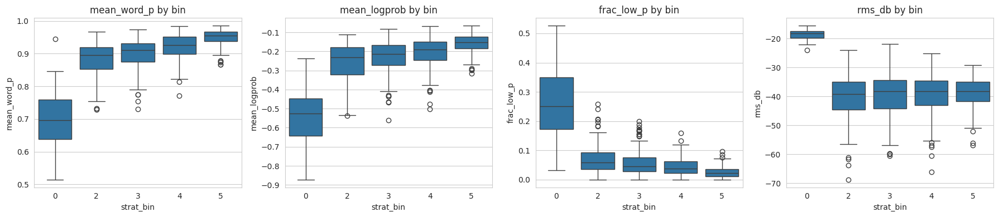

In [43]:
conf = ["mean_word_p", "mean_logprob", "min_logprob", "frac_low_p", "max_no_speech",
        "max_compress", "words_per_min", "uniq_ratio"]
acou = ["rms_db", "silence_ratio", "peak"]

print("=== Group means by stratification bin ===")
print(d.groupby("strat_bin")[conf].mean().round(3))

print("\n=== Spearman with label: all clips vs label>0 only ===")
nz = d[~d["is_zero"]]
rows = []
for c in conf + acou:
    rows.append({"feature": c,
                 "all": spearmanr(d[c], d["label"], nan_policy="omit")[0],
                 "label>0": spearmanr(nz[c], nz["label"], nan_policy="omit")[0]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

print("\n=== Zero-class separability (AUC for label=0 vs rest; 0.5 = useless, 1.0 = perfect) ===")
auc = {}
for c in conf + acou:
    x = d[c].fillna(d[c].median())
    a = roc_auc_score(d["is_zero"], x)
    auc[c] = max(a, 1 - a)
print(pd.Series(auc).sort_values(ascending=False).round(3))

# Range overlap on the confidence feature that looks best
for c in ["mean_word_p", "rms_db"]:
    z, r = d.loc[d.is_zero, c], d.loc[~d.is_zero, c]
    print(f"\n{c}: zero range [{z.min():.2f}, {z.max():.2f}] | rest range [{r.min():.2f}, {r.max():.2f}] | "
          f"rest clips inside zero range: {int(((r >= z.min()) & (r <= z.max())).sum())}")

import matplotlib.pyplot as plt, seaborn as sns
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, c in zip(ax, ["mean_word_p", "mean_logprob", "frac_low_p", "rms_db"]):
    sns.boxplot(x="strat_bin", y=c, data=d, ax=a); a.set_title(f"{c} by bin")
plt.tight_layout(); plt.show()

**FEARTURE ENGINEERING**

In [46]:
import re, numpy as np, pandas as pd
from collections import Counter

asr = pd.read_pickle("/kaggle/input/datasets/mridul1028/transcriber/asr_large_v3_train.pkl")
d = train_df.merge(asr[["filename", "text", "words", "segments", "n_words",
                        "words_per_min", "mean_word_p"]], on="filename", how="left")
assert d["text"].notna().all() and len(d) == 769

F = pd.DataFrame({"filename": d["filename"]})   # feature table, one row per clip

# ---------- Block A: ASR confidence ----------
wp = d["words"].apply(lambda w: np.array([x["p"] for x in w]) if w else np.array([np.nan]))
F["mean_word_p"]   = wp.apply(np.nanmean)
F["std_word_p"]    = wp.apply(np.nanstd)
F["p10_word_p"]    = wp.apply(lambda a: np.nanpercentile(a, 10))
F["frac_low_p"]    = wp.apply(lambda a: np.nanmean(a < 0.5))
F["mean_logprob"]  = d["segments"].apply(lambda s: np.mean([x["avg_logprob"] for x in s]) if s else np.nan)
F["min_logprob"]   = d["segments"].apply(lambda s: min([x["avg_logprob"] for x in s], default=np.nan))
F["max_no_speech"] = d["segments"].apply(lambda s: max([x["no_speech_prob"] for x in s], default=np.nan))
F["max_compress"]  = d["segments"].apply(lambda s: max([x["compression_ratio"] for x in s], default=np.nan))
F["n_segs"]        = d["segments"].apply(len)

# ---------- Block A: pace and word timing ----------
def timing_feats(words):
    keys = ["span_wps", "gap_mean", "gap_std", "gaps_gt05_per_min", "gaps_gt1_per_min",
            "frac_time_in_gaps", "word_dur_mean"]
    if len(words) < 5:
        return dict.fromkeys(keys, np.nan)
    s = np.array([w["s"] for w in words]); e = np.array([w["e"] for w in words])
    gaps = np.clip(s[1:] - e[:-1], 0, None)
    span = max(e[-1] - s[0], 1e-6)
    return {"span_wps": len(words) / span,
            "gap_mean": gaps.mean(), "gap_std": gaps.std(),
            "gaps_gt05_per_min": (gaps > 0.5).sum() / (span / 60),
            "gaps_gt1_per_min": (gaps > 1.0).sum() / (span / 60),
            "frac_time_in_gaps": gaps[gaps > 0.25].sum() / span,
            "word_dur_mean": (e - s).mean()}
F = pd.concat([F, pd.DataFrame(d["words"].apply(timing_feats).tolist())], axis=1)
F["words_per_min"] = d["words_per_min"].values
F["n_words_raw"]   = d["n_words"].values

# ---------- Block A: repetition ----------
def rep_feats(t):
    w = re.findall(r"[a-z']+", t.lower())
    if len(w) < 6:
        return {"max_tri_rep": 0, "rep_tok_frac": 0.0, "uniq_ratio": 1.0, "max_word_run": 1, "imm_repeats": 0}
    tri = Counter(zip(w, w[1:], w[2:]))
    run = best = 1
    for a, b in zip(w, w[1:]):
        run = run + 1 if a == b else 1
        best = max(best, run)
    # immediate repeats of a word or two-word phrase ("in the in the", "the the")
    imm = sum(a == b for a, b in zip(w, w[1:])) + sum(w[i:i+2] == w[i+2:i+4] for i in range(len(w) - 3))
    return {"max_tri_rep": max(tri.values()),
            "rep_tok_frac": min(sum(c * 3 for c in tri.values() if c >= 3) / len(w), 1.0),
            "uniq_ratio": len(set(w)) / len(w), "max_word_run": best, "imm_repeats": imm}
F = pd.concat([F, pd.DataFrame(d["text"].apply(rep_feats).tolist())], axis=1)

# ---------- Block B: acoustic (from Phases 2 and 3) ----------
acoustic = ["rms_db", "silence_ratio", "peak", "speech_ratio", "n_pauses", "mean_pause",
            "max_pause", "pauses_per_min", "mean_speech_seg", "n_speech_segs", "orig_len_s", "trimmed_s"]
for c in acoustic:
    F[c] = d[c].values

print("Blocks A+B:", F.shape, "| NaNs per column (non-zero only):")
print(F.isna().sum()[F.isna().sum() > 0])

Blocks A+B: (769, 36) | NaNs per column (non-zero only):
span_wps             1
gap_mean             1
gap_std              1
gaps_gt05_per_min    1
gaps_gt1_per_min     1
frac_time_in_gaps    1
word_dur_mean        1
dtype: int64


In [56]:
import os, re, numpy as np, pandas as pd, torch
from tqdm.auto import tqdm
from transformers import GPT2LMHeadModel, GPT2TokenizerFast, AutoTokenizer, AutoModel

W = "/kaggle/working/"
# assert os.path.exists(W + "asr_large_v3_train.pkl"), "ASR pickle missing: transcripts would need redoing"

F = pd.read_pickle(W + "features_v1.pkl")
new_cols = ["had_edge_thanks", "n_words_clean", "lm_mean_nll", "lm_med_nll", "lm_p90_nll", "lm_frac_gt8"]
F = F.drop(columns=[c for c in new_cols if c in F.columns])      # safe to rerun

asr = pd.read_pickle('/kaggle/input/datasets/mridul1028/transcriber/asr_large_v3_train.pkl').drop_duplicates("filename").set_index("filename")
text = F["filename"].map(asr["text"])
assert text.notna().all(), "some transcripts missing"

# ---- clean Whisper edge phrases (same rule as before) ----
PHR = r"(?:thanks for watching|thank you for watching|thank you very much|thank you|see you soon|see you next time)"
START = re.compile(rf"^\s*(?:{PHR}[\s.!,]*)+", re.I)
END   = re.compile(rf"(?:[\s.!,]*{PHR})+[\s.!,]*$", re.I)
def clean(t):
    c = END.sub("", START.sub("", t)).strip()
    return c if len(c.split()) >= 3 else t
clean_text = text.apply(clean)
F["had_edge_thanks"] = (clean_text != text).astype(int).values
F["n_words_clean"]   = clean_text.str.split().apply(len).values
print("Clips with stripped edges:", int(F["had_edge_thanks"].sum()))

# ---- GPT-2 surprisal ----
gtok = GPT2TokenizerFast.from_pretrained("gpt2")
lm = GPT2LMHeadModel.from_pretrained("gpt2").to("cuda").eval()
@torch.no_grad()
def lm_feats(t):
    ids = gtok(gtok.bos_token + t, return_tensors="pt", truncation=True, max_length=1024).input_ids.to("cuda")
    if ids.shape[1] < 3:
        return dict(lm_mean_nll=np.nan, lm_med_nll=np.nan, lm_p90_nll=np.nan, lm_frac_gt8=np.nan)
    nll = torch.nn.functional.cross_entropy(lm(ids).logits[0, :-1].float(), ids[0, 1:], reduction="none").cpu().numpy()
    return dict(lm_mean_nll=nll.mean(), lm_med_nll=np.median(nll),
                lm_p90_nll=np.percentile(nll, 90), lm_frac_gt8=float((nll > 8).mean()))
lf = pd.DataFrame([lm_feats(t) for t in tqdm(clean_text)])
F = pd.concat([F.reset_index(drop=True), lf], axis=1)
del lm; torch.cuda.empty_cache()

# ---- save features + texts ----
F.to_pickle(W + "features_v1.pkl")
pd.DataFrame({"filename": F["filename"], "text": text.values, "clean_text": clean_text.values}).to_pickle(W + "texts_v1.pkl")
print("features_v1:", F.shape, "(expected (769, 44))")

# ---- RoBERTa embeddings, all 13 layers ----
tok = AutoTokenizer.from_pretrained("roberta-base")
enc = AutoModel.from_pretrained("roberta-base").to("cuda").eval().half()
@torch.no_grad()
def embed_text(txts, bs=16):
    out = []
    for i in tqdm(range(0, len(txts), bs)):
        b = tok(list(txts[i:i+bs]), padding=True, truncation=True, max_length=512, return_tensors="pt").to("cuda")
        hs = enc(**b, output_hidden_states=True).hidden_states
        m = b["attention_mask"].unsqueeze(-1).float()
        out.append(torch.stack([(h.float() * m).sum(1) / m.sum(1) for h in hs], 1).cpu().numpy())
    return np.concatenate(out)
E = embed_text(clean_text.tolist())
np.save(W + "emb_text_roberta.npy", E)
print("Embeddings:", E.shape, "| NaNs:", int(np.isnan(E).sum()))

Clips with stripped edges: 30


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

  0%|          | 0/769 [00:00<?, ?it/s]

features_v1: (769, 44) (expected (769, 44))


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/49 [00:00<?, ?it/s]

Embeddings: (769, 13, 768) | NaNs: 0


**CV HARNESS**

In [59]:
import numpy as np, pandas as pd, warnings
from scipy.stats import pearsonr
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
warnings.filterwarnings("ignore")

# ---------- data ----------
F = pd.read_pickle("/kaggle/working/features_v1.pkl")
y = F["label"].values
strat = F["strat_bin"].values
FEATS = [c for c in F.columns if c not in ("filename", "label", "strat_bin")]
X = F[FEATS].reset_index(drop=True)
GATE_FEATS = ["rms_db", "silence_ratio", "mean_word_p", "mean_logprob"]
print("Samples:", len(X), "| features:", len(FEATS), "| zero clips:", int((y == 0).sum()))
FLOOR = np.sqrt(((y - y.mean()) ** 2).mean())
print(f"Mean-predictor RMSE (floor): {FLOOR:.4f}")

# ---------- metrics ----------
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
def mae(a, b):  return float(np.mean(np.abs(a - b)))
def pear(a, b):
    return float(pearsonr(a, b)[0]) if np.std(b) > 1e-9 else np.nan

# ---------- model factories ----------
def prep(): return [SimpleImputer(strategy="median"), StandardScaler()]
MODELS = {
    "Mean predictor": lambda: DummyRegressor(strategy="mean"),
    "Ridge":          lambda: make_pipeline(*prep(), Ridge(alpha=10.0)),
    "SVR (rbf)":      lambda: make_pipeline(*prep(), SVR(C=1.0, epsilon=0.2)),
    "HistGB":         lambda: HistGradientBoostingRegressor(
                          max_iter=200, learning_rate=0.05, max_depth=3,
                          min_samples_leaf=15, random_state=42),
}
def make_gate():
    return make_pipeline(*prep(), LogisticRegression(class_weight="balanced", max_iter=1000))

# ---------- fit / predict: gate + grammar model ----------
def fit_system(Xtr, ytr, factory, use_gate):
    gate = reg = None
    if use_gate:
        gate = make_gate().fit(Xtr[GATE_FEATS], (ytr == 0).astype(int))
        reg = factory().fit(Xtr[ytr > 0], ytr[ytr > 0])      # grammar model: label > 0 only
    else:
        reg = factory().fit(Xtr, ytr)                         # one model for everything
    return gate, reg

def predict_system(gate, reg, Xte):
    p = np.clip(reg.predict(Xte), 0, 5)
    zero_flag = np.zeros(len(Xte), bool)
    if gate is not None:
        zero_flag = gate.predict_proba(Xte[GATE_FEATS])[:, 1] > 0.5
        p = np.where(zero_flag, 0.0, p)
    return p, zero_flag

# ---------- the evaluation harness ----------
N_SPLITS, N_REPEATS = 5, 3
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=42)
splits = list(rskf.split(X, strat))          # same folds for every model: fair comparison

def cv_eval(name, factory, use_gate):
    oof = np.zeros((N_REPEATS, len(y)))
    train_rmse, gate_fn, gate_fp = [], 0, 0
    for i, (tr, te) in enumerate(splits):
        gate, reg = fit_system(X.iloc[tr], y[tr], factory, use_gate)
        oof[i // N_SPLITS, te], zf = predict_system(gate, reg, X.iloc[te])
        p_tr, _ = predict_system(gate, reg, X.iloc[tr])
        train_rmse.append(rmse(y[tr], p_tr))
        if use_gate:
            gate_fn += int(((y[te] == 0) & ~zf).sum())        # zero clips the gate missed
            gate_fp += int(((y[te] != 0) & zf).sum())         # normal clips wrongly zeroed
    per_rep = [(rmse(y, o), pear(y, o), mae(y, o)) for o in oof]
    nz = y > 0
    res = {
        "model": name, "gate": use_gate,
        "CV RMSE": np.mean([r[0] for r in per_rep]), "RMSE sd": np.std([r[0] for r in per_rep]),
        "CV Pearson": np.nanmean([r[1] for r in per_rep]),
        "CV MAE": np.mean([r[2] for r in per_rep]),
        "RMSE (label>0)": np.mean([rmse(y[nz], o[nz]) for o in oof]),
        "Train RMSE (in-fold)": np.mean(train_rmse),
        "gate missed zeros": gate_fn, "gate false zeros": gate_fp,
    }
    # full fit on all 769 clips: the compulsory training RMSE
    gate, reg = fit_system(X, y, factory, use_gate)
    p_full, _ = predict_system(gate, reg, X)
    res["Train RMSE (full fit)"] = rmse(y, p_full)
    return res, oof

results, OOF = [], {}
for name, fac in MODELS.items():
    for use_gate in (False, True):
        r, o = cv_eval(name, fac, use_gate)
        results.append(r); OOF[(name, use_gate)] = o
        print(f"done: {name:15s} gate={use_gate!s:5s} CV RMSE={r['CV RMSE']:.3f}  Pearson={r['CV Pearson']:.3f}")

res_df = pd.DataFrame(results).sort_values("CV RMSE").reset_index(drop=True)
pd.set_option("display.width", 220)
print(f"\n(CV = {N_SPLITS}-fold x {N_REPEATS} repeats; floor RMSE = {FLOOR:.3f})")
print(res_df.round(3).to_string(index=False))
res_df.to_csv("/kaggle/working/baseline_results_v1.csv", index=False)

Samples: 769 | features: 41 | zero clips: 37
Mean-predictor RMSE (floor): 1.2382
done: Mean predictor  gate=False CV RMSE=1.238  Pearson=-0.011
done: Mean predictor  gate=True  CV RMSE=1.016  Pearson=0.574
done: Ridge           gate=False CV RMSE=0.688  Pearson=0.832
done: Ridge           gate=True  CV RMSE=0.708  Pearson=0.822
done: SVR (rbf)       gate=False CV RMSE=0.732  Pearson=0.808
done: SVR (rbf)       gate=True  CV RMSE=0.721  Pearson=0.813
done: HistGB          gate=False CV RMSE=0.699  Pearson=0.826
done: HistGB          gate=True  CV RMSE=0.723  Pearson=0.813

(CV = 5-fold x 3 repeats; floor RMSE = 1.238)
         model  gate  CV RMSE  RMSE sd  CV Pearson  CV MAE  RMSE (label>0)  Train RMSE (in-fold)  gate missed zeros  gate false zeros  Train RMSE (full fit)
         Ridge False    0.688    0.004       0.832   0.540           0.691                 0.651                  0                 0                  0.655
        HistGB False    0.699    0.003       0.826   0.545   

Best config: ('Ridge', False) | CV RMSE 0.688 | Pearson 0.832

Error by label bin (repeat 0):
       n   rmse    mae   bias
bin                          
0     37  0.625  0.322  0.322
2    106  0.937  0.806  0.753
3    253  0.610  0.471  0.261
4    188  0.580  0.462 -0.221
5    185  0.752  0.622 -0.600

Share of squared error from the 37 zero clips: 3.9%


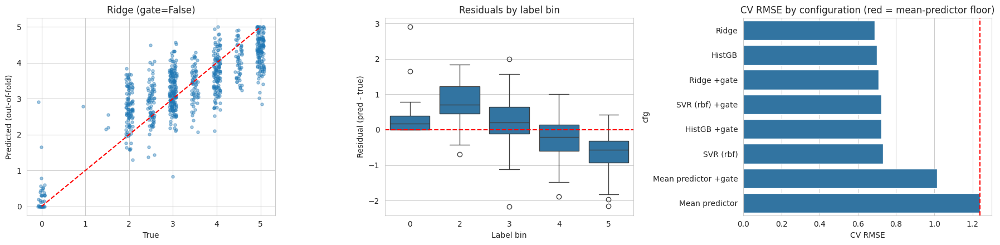

In [60]:
import matplotlib.pyplot as plt, seaborn as sns

best = res_df.iloc[0]
key = (best["model"], bool(best["gate"]))
o = OOF[key][0]                                   # out-of-fold predictions, repeat 0
print(f"Best config: {key} | CV RMSE {best['CV RMSE']:.3f} | Pearson {best['CV Pearson']:.3f}")

# error by strat bin
by = pd.DataFrame({"bin": strat, "err2": (y - o) ** 2, "abs": np.abs(y - o), "bias": o - y})
print("\nError by label bin (repeat 0):")
print(by.groupby("bin").agg(n=("err2", "size"), rmse=("err2", lambda s: np.sqrt(s.mean())),
                            mae=("abs", "mean"), bias=("bias", "mean")).round(3))

# share of total squared error coming from zero clips
share0 = by.loc[by.bin == 0, "err2"].sum() / by["err2"].sum()
print(f"\nShare of squared error from the 37 zero clips: {share0:.1%}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
jit = np.random.RandomState(0).uniform(-0.08, 0.08, len(y))
ax[0].scatter(y + jit, o, alpha=0.4, s=14); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set_xlabel("True"); ax[0].set_ylabel("Predicted (out-of-fold)")
ax[0].set_title(f"{key[0]} (gate={key[1]})")
sns.boxplot(x=strat, y=o - y, ax=ax[1]); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Label bin"); ax[1].set_ylabel("Residual (pred - true)"); ax[1].set_title("Residuals by label bin")
plot_df = res_df.assign(cfg=lambda d: d["model"] + np.where(d["gate"], " +gate", ""))
sns.barplot(y="cfg", x="CV RMSE", data=plot_df, ax=ax[2]); ax[2].axvline(FLOOR, color="r", ls="--")
ax[2].set_title("CV RMSE by configuration (red = mean-predictor floor)")
plt.tight_layout(); plt.show()

Ablation 


In [61]:
import numpy as np, pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

GROUPS = {
    "Confidence": ["mean_word_p","std_word_p","p10_word_p","frac_low_p","mean_logprob",
                   "min_logprob","max_no_speech","max_compress","n_segs"],
    "Text/LM":    ["lm_mean_nll","lm_med_nll","lm_p90_nll","lm_frac_gt8",
                   "max_tri_rep","rep_tok_frac","uniq_ratio","max_word_run","imm_repeats",
                   "n_words_clean","had_edge_thanks"],
    "Timing":     ["span_wps","gap_mean","gap_std","gaps_gt05_per_min","gaps_gt1_per_min",
                   "frac_time_in_gaps","word_dur_mean","words_per_min","n_words_raw"],
    "Acoustic":   ["rms_db","silence_ratio","peak","speech_ratio","n_pauses","mean_pause",
                   "max_pause","pauses_per_min","mean_speech_seg","n_speech_segs",
                   "orig_len_s","trimmed_s"],
}
allg = [c for g in GROUPS.values() for c in g]
assert sorted(allg) == sorted(FEATS) and len(set(allg)) == len(allg), \
    (set(FEATS) - set(allg), set(allg) - set(FEATS))

def ridge(): return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))

def run_cols(cols):
    """Same folds as the baseline; returns per-repeat OOF metrics."""
    oof = np.zeros((N_REPEATS, len(y)))
    for i, (tr, te) in enumerate(splits):
        m = ridge().fit(X.iloc[tr][cols], y[tr])
        oof[i // N_SPLITS, te] = np.clip(m.predict(X.iloc[te][cols]), 0, 5)
    r = [rmse(y, o) for o in oof]; p = [pear(y, o) for o in oof]
    nz = y > 0
    return {"CV RMSE": np.mean(r), "RMSE sd": np.std(r), "CV Pearson": np.mean(p),
            "RMSE (label>0)": np.mean([rmse(y[nz], o[nz]) for o in oof]),
            "n_feats": len(cols)}

rows = []
# 1. each group alone
for g, cols in GROUPS.items():
    rows.append({"experiment": "alone", "config": g, **run_cols(cols)})
# 2. cumulative
acc = []
for g in GROUPS:
    acc += GROUPS[g]
    rows.append({"experiment": "cumulative", "config": "+".join(list(GROUPS)[:len(rows) - 3]), **run_cols(acc)})
# 3. leave one group out
for g in GROUPS:
    cols = [c for c in allg if c not in GROUPS[g]]
    rows.append({"experiment": "leave-out", "config": f"all - {g}", **run_cols(cols)})
# reference and no-confidence
rows.append({"experiment": "reference", "config": "all 41", **run_cols(allg)})

abl = pd.DataFrame(rows)
# fix cumulative labels explicitly (clearer than the slice trick above)
names = list(GROUPS)
abl.loc[abl.experiment == "cumulative", "config"] = [" + ".join(names[:k+1]) for k in range(4)]
abl["vs all-41 RMSE"] = abl["CV RMSE"] - abl.loc[abl.config == "all 41", "CV RMSE"].iloc[0]
pd.set_option("display.width", 200)
print(f"(floor RMSE = {FLOOR:.3f})")
print(abl.round(3).to_string(index=False))
abl.to_csv("/kaggle/working/ablation_v1.csv", index=False)

(floor RMSE = 1.238)
experiment                                   config  CV RMSE  RMSE sd  CV Pearson  RMSE (label>0)  n_feats  vs all-41 RMSE
     alone                               Confidence    0.822    0.002       0.749           0.788        9           0.134
     alone                                  Text/LM    1.098    0.003       0.462           0.826       11           0.410
     alone                                   Timing    1.152    0.003       0.366           0.951        9           0.465
     alone                                 Acoustic    0.940    0.003       0.651           0.959       12           0.252
cumulative                               Confidence    0.822    0.002       0.749           0.788        9           0.134
cumulative                     Confidence + Text/LM    0.780    0.003       0.777           0.732       20           0.092
cumulative            Confidence + Text/LM + Timing    0.769    0.002       0.784           0.723       29           0

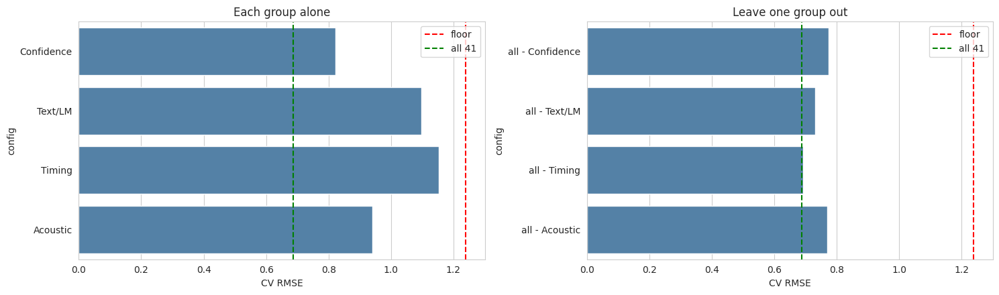


Top 15 standardized Ridge coefficients (full fit):
                    coef       group
mean_word_p        0.561  Confidence
mean_speech_seg   -0.455    Acoustic
frac_low_p         0.355  Confidence
uniq_ratio         0.349     Text/LM
orig_len_s         0.282    Acoustic
p10_word_p         0.243  Confidence
rms_db            -0.190    Acoustic
gaps_gt05_per_min  0.142      Timing
lm_mean_nll       -0.134     Text/LM
words_per_min      0.128      Timing
max_pause         -0.110    Acoustic
mean_logprob       0.105  Confidence
gap_std            0.104      Timing
lm_med_nll        -0.090     Text/LM
span_wps           0.085      Timing


In [62]:
import matplotlib.pyplot as plt, seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, exp, title in [(ax[0], "alone", "Each group alone"), (ax[1], "leave-out", "Leave one group out")]:
    s = abl[abl.experiment == exp]
    sns.barplot(y="config", x="CV RMSE", data=s, ax=a, color="steelblue")
    a.axvline(FLOOR, color="r", ls="--", label="floor")
    a.axvline(abl.loc[abl.config == "all 41", "CV RMSE"].iloc[0], color="g", ls="--", label="all 41")
    a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

# standardized coefficients of the full Ridge fit (explanatory only, not CV)
m = ridge().fit(X[allg], y)
coef = pd.Series(m[-1].coef_, index=allg)
grp = {c: g for g, cols in GROUPS.items() for c in cols}
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
print("\nTop 15 standardized Ridge coefficients (full fit):")
print(pd.DataFrame({"coef": top.round(3), "group": [grp[c] for c in top.index]}).to_string())

**TEXT EMBEDDINGS**

In [63]:
import torch, numpy as np, pandas as pd
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

F  = pd.read_pickle("/kaggle/working/features_v1.pkl")
T  = pd.read_pickle("/kaggle/working/texts_v1.pkl")
T  = T.set_index("filename").loc[F["filename"]].reset_index()   # same row order as X
assert (T["filename"].values == F["filename"].values).all()

tok = AutoTokenizer.from_pretrained("roberta-base")
enc = AutoModel.from_pretrained("roberta-base").to("cuda").eval().half()

@torch.no_grad()
def embed_text(txts, bs=16):
    out = []
    for i in tqdm(range(0, len(txts), bs)):
        b = tok(list(txts[i:i+bs]), padding=True, truncation=True,
                max_length=512, return_tensors="pt").to("cuda")
        hs = enc(**b, output_hidden_states=True).hidden_states     # 13 x (B, L, 768)
        m = b["attention_mask"].unsqueeze(-1).float()
        layers = torch.stack([(h.float() * m).sum(1) / m.sum(1) for h in hs], 1)
        out.append(layers.cpu().numpy())
    return np.concatenate(out)

E_text = embed_text(T["clean_text"].tolist())
print("Text embeddings:", E_text.shape, "| NaNs:", int(np.isnan(E_text).sum()))
n_trunc = sum(len(tok(t)["input_ids"]) > 512 for t in T["clean_text"])
print("Transcripts longer than 512 tokens (truncated):", n_trunc)
np.save("/kaggle/working/emb_text_roberta.npy", E_text)
del enc; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/49 [00:00<?, ?it/s]

Text embeddings: (769, 13, 768) | NaNs: 0
Transcripts longer than 512 tokens (truncated): 0


In [67]:
import os
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

E = {}
if os.path.exists("/kaggle/working/emb_text_roberta.npy"):
    E["text"] = np.load("/kaggle/working/emb_text_roberta.npy")
if os.path.exists("/kaggle/working/emb_audio_w2v2.npy"):
    E["audio"] = np.load("/kaggle/working/emb_audio_w2v2.npy")
print("Embedding sources available:", list(E))

Xe = X[FEATS].values.astype(float)

def build(use_eng, specs):
    """specs = [(source, layer, k_pca)] -> (matrix, ColumnTransformer-ready blocks)"""
    parts, blocks, c = [], [], 0
    if use_eng:
        parts.append(Xe); blocks.append(("eng", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                                         list(range(c, c + Xe.shape[1])))); c += Xe.shape[1]
    for s, layer, k in specs:
        M = E[s][:, layer, :]; parts.append(M)
        blocks.append((f"{s}{layer}", make_pipeline(StandardScaler(), PCA(k, whiten=True, random_state=0)),
                       list(range(c, c + M.shape[1])))); c += M.shape[1]
    return np.hstack(parts), blocks

def run(use_eng, specs, alpha=10.0):
    Z, blocks = build(use_eng, specs)
    oof = np.zeros((N_REPEATS, len(y)))
    for i, (tr, te) in enumerate(splits):
        m = make_pipeline(ColumnTransformer(blocks), Ridge(alpha=alpha)).fit(Z[tr], y[tr])
        oof[i // N_SPLITS, te] = np.clip(m.predict(Z[te]), 0, 5)
    nz = y > 0
    r = [rmse(y, o) for o in oof]
    return {"CV RMSE": np.mean(r), "RMSE sd": np.std(r),
            "CV Pearson": np.mean([pear(y, o) for o in oof]),
            "RMSE (label>0)": np.mean([rmse(y[nz], o[nz]) for o in oof])}

rows = []
# 1. embeddings alone: grid over layer and PCA size
for s in E:
    for layer in (6, 9, 12):
        for k in (10, 20, 40):
            rows.append({"config": f"{s} L{layer} k{k} alone", "source": s, "layer": layer, "k": k,
                         **run(False, [(s, layer, k)])})
grid = pd.DataFrame(rows)
print(f"(floor = {FLOOR:.3f}; engineered-only baseline = 0.688)")
print(grid.round(3).to_string(index=False))

# 2. engineered features + the best layer/k per source
best = {s: grid[grid.source == s].sort_values("CV RMSE").iloc[0] for s in E}
specs = {s: (s, int(b["layer"]), int(b["k"])) for s, b in best.items()}
combo = [{"config": "engineered only (41)", **run(True, [])}]
for s in E:
    combo.append({"config": f"engineered + {s} (L{specs[s][1]}, k{specs[s][2]})", **run(True, [specs[s]])})
if len(E) == 2:
    combo.append({"config": "engineered + text + audio", **run(True, list(specs.values()))})
    combo.append({"config": "text + audio only (no engineered)", **run(False, list(specs.values()))})
combo = pd.DataFrame(combo)
print("\n", combo.round(3).to_string(index=False))
combo.to_csv("/kaggle/working/embedding_results_v1.csv", index=False)

Embedding sources available: ['text']
(floor = 1.238; engineered-only baseline = 0.688)
            config source  layer  k  CV RMSE  RMSE sd  CV Pearson  RMSE (label>0)
 text L6 k10 alone   text      6 10    1.017    0.002       0.570           0.769
 text L6 k20 alone   text      6 20    0.938    0.006       0.653           0.722
 text L6 k40 alone   text      6 40    0.941    0.005       0.650           0.727
 text L9 k10 alone   text      9 10    1.010    0.004       0.579           0.768
 text L9 k20 alone   text      9 20    0.922    0.003       0.667           0.713
 text L9 k40 alone   text      9 40    0.917    0.004       0.672           0.716
text L12 k10 alone   text     12 10    1.026    0.005       0.559           0.768
text L12 k20 alone   text     12 20    0.991    0.005       0.600           0.759
text L12 k40 alone   text     12 40    0.948    0.003       0.643           0.728

                      config  CV RMSE  RMSE sd  CV Pearson  RMSE (label>0)
       engineere

**FINAL REULT**

Ridge alpha search (engineered + text):
 alpha  CV RMSE  RMSE sd (repeats)  CV Pearson  CV MAE  CV RMSE (label>0)
     1   0.6275             0.0046      0.8621  0.4904             0.6228
     3   0.6265             0.0045      0.8626  0.4896             0.6220
    10   0.6261             0.0041      0.8629  0.4894             0.6212
    30   0.6285             0.0034      0.8620  0.4920             0.6217
   100   0.6384             0.0024      0.8583  0.5026             0.6272
-> chosen alpha = 10.0

 FINAL RESULTS: Grammar Scoring Engine (769 labelled training clips)
 Training RMSE (full fit, compulsory) : 0.5602
 Training Pearson (full fit)          : 0.8926
 Training MAE (full fit)              : 0.4402
------------------------------------------------------------------
 CV RMSE   (5-fold x 3 repeats)         : 0.6261  (sd 0.0041)
 CV Pearson                           : 0.8629
 CV MAE                               : 0.4894
 CV RMSE on label>0 clips only        : 0.6212
------------

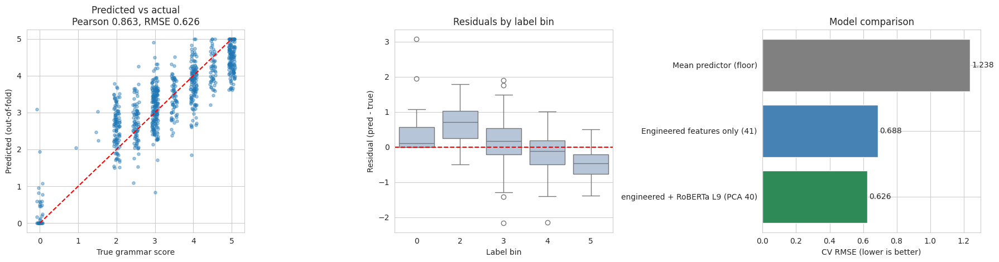


NOTES FOR THE REPORT
- Training RMSE is from one fit on all 769 clips. CV RMSE/Pearson come from out-of-fold predictions
  (5-fold x 3 repeats, stratified on label bins) and are the honest performance estimate.
- PCA and scaling are fitted inside each training fold, so no information leaks into validation folds.
- Ridge alpha, embedding layer (9) and PCA size (40) were chosen on these same folds, so CV figures
  are slightly optimistic. Repeat sd reflects fold shuffling only, not sampling uncertainty.
- No speaker IDs are available, so clips from the same speaker may sit in both train and validation.
- Predictions regress toward the mean: low scores are over-predicted, top scores under-predicted.
- Features mix grammar with intelligibility (ASR confidence, noise); the model predicts the score well
  but should not be read as measuring grammar in isolation.



In [68]:
# =====================================================================
# FINAL RESULTS: Grammar Scoring Engine
# Model : engineered features (41) + RoBERTa layer-9 text embedding
#         (PCA, k=40, whitened) -> Ridge regression, output clipped to [0, 5]
# Reports: Training RMSE (compulsory), CV RMSE, Pearson, MAE
# =====================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
from scipy.stats import pearsonr
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
warnings.filterwarnings("ignore")

# ---------- 1. Data ----------
F = pd.read_pickle("/kaggle/working/features_v1.pkl")
E = np.load("/kaggle/working/emb_text_roberta.npy")            # (769, 13, 768)
y, strat = F["label"].values, F["strat_bin"].values
FEATS = [c for c in F.columns if c not in ("filename", "label", "strat_bin")]
Xeng = F[FEATS].values.astype(float)
Xtxt = E[:, 9, :]                                               # layer 9 (best in CV)
Z = np.hstack([Xeng, Xtxt])
n_eng = Xeng.shape[1]
assert len(y) == 769 and Z.shape[0] == E.shape[0]

# ---------- 2. Metrics ----------
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
mae  = lambda a, b: float(np.mean(np.abs(a - b)))
pear = lambda a, b: float(pearsonr(a, b)[0])
FLOOR = rmse(y, np.full_like(y, y.mean()))                      # mean-predictor RMSE

# ---------- 3. Model factory ----------
def make_model(alpha, use_text=True):
    blocks = [("eng", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
               list(range(n_eng)))]
    if use_text:   # PCA is fitted inside each training fold only (no leakage)
        blocks.append(("txt", make_pipeline(StandardScaler(), PCA(40, whiten=True, random_state=0)),
                       list(range(n_eng, Z.shape[1]))))
    return make_pipeline(ColumnTransformer(blocks), Ridge(alpha=alpha))

# ---------- 4. Cross-validation (same folds as all earlier experiments) ----------
N_SPLITS, N_REPEATS = 5, 3
splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS,
                                      random_state=42).split(Z, strat))

def cv(alpha, use_text=True):
    oof = np.zeros((N_REPEATS, len(y)))
    for i, (tr, te) in enumerate(splits):
        m = make_model(alpha, use_text).fit(Z[tr], y[tr])
        oof[i // N_SPLITS, te] = np.clip(m.predict(Z[te]), 0, 5)
    return oof

def summarize(oof):
    r = [rmse(y, o) for o in oof]; p = [pear(y, o) for o in oof]; a = [mae(y, o) for o in oof]
    nz = y > 0
    return {"CV RMSE": np.mean(r), "RMSE sd (repeats)": np.std(r), "CV Pearson": np.mean(p),
            "CV MAE": np.mean(a), "CV RMSE (label>0)": np.mean([rmse(y[nz], o[nz]) for o in oof])}

# Small alpha search. Note: picked on the same folds, so slightly optimistic.
alpha_rows = [{"alpha": a, **summarize(cv(a))} for a in (1, 3, 10, 30, 100)]
alpha_df = pd.DataFrame(alpha_rows)
BEST_ALPHA = float(alpha_df.sort_values("CV RMSE").iloc[0]["alpha"])
print("Ridge alpha search (engineered + text):")
print(alpha_df.round(4).to_string(index=False))
print(f"-> chosen alpha = {BEST_ALPHA}\n")

# ---------- 5. Final numbers ----------
oof_final = cv(BEST_ALPHA, True)
oof_eng   = cv(10.0, False)                                     # engineered-only reference

final = make_model(BEST_ALPHA, True).fit(Z, y)                  # fit on ALL 769 clips
p_train = np.clip(final.predict(Z), 0, 5)
train_rmse, train_pear, train_mae = rmse(y, p_train), pear(y, p_train), mae(y, p_train)

res = pd.DataFrame([
    {"Model": "Mean predictor (floor)", "CV RMSE": FLOOR, "CV Pearson": 0.0},
    {"Model": "Engineered features only (41)", **{k: v for k, v in summarize(oof_eng).items()
                                                   if k in ("CV RMSE", "CV Pearson", "CV MAE")}},
    {"Model": "FINAL: engineered + RoBERTa L9 (PCA 40)", **{k: v for k, v in summarize(oof_final).items()
                                                            if k in ("CV RMSE", "CV Pearson", "CV MAE")}},
])
res.to_csv("/kaggle/working/final_results.csv", index=False)

S = summarize(oof_final)
print("=" * 66)
print(" FINAL RESULTS: Grammar Scoring Engine (769 labelled training clips)")
print("=" * 66)
print(f" Training RMSE (full fit, compulsory) : {train_rmse:.4f}")
print(f" Training Pearson (full fit)          : {train_pear:.4f}")
print(f" Training MAE (full fit)              : {train_mae:.4f}")
print("-" * 66)
print(f" CV RMSE   ({N_SPLITS}-fold x {N_REPEATS} repeats)         : {S['CV RMSE']:.4f}  (sd {S['RMSE sd (repeats)']:.4f})")
print(f" CV Pearson                           : {S['CV Pearson']:.4f}")
print(f" CV MAE                               : {S['CV MAE']:.4f}")
print(f" CV RMSE on label>0 clips only        : {S['CV RMSE (label>0)']:.4f}")
print("-" * 66)
print(f" Baseline: always predict the mean    : RMSE {FLOOR:.4f}")
print(f" RMSE reduction vs baseline           : {(1 - S['CV RMSE'] / FLOOR):.1%}")
print(f" Train-vs-CV RMSE gap                 : {S['CV RMSE'] - train_rmse:.4f}")
print("=" * 66)
print("\nModel comparison (CV):")
print(res.round(4).to_string(index=False))

# ---------- 6. Per-label-bin error ----------
o = oof_final[0]
by = (pd.DataFrame({"bin": strat, "se": (y - o) ** 2, "ae": np.abs(y - o), "bias": o - y})
        .groupby("bin").agg(n=("se", "size"), RMSE=("se", lambda s: np.sqrt(s.mean())),
                            MAE=("ae", "mean"), bias=("bias", "mean")).round(3))
print("\nError by label bin (CV repeat 0; bin 0 = noise clips, 2 = labels 1-2, 3 = 2.5-3, 4 = 3.5-4, 5 = 4.5-5):")
print(by)

# ---------- 7. Plots ----------
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
jit = np.random.RandomState(0).uniform(-0.08, 0.08, len(y))
ax[0].scatter(y + jit, o, alpha=0.4, s=14); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set(xlabel="True grammar score", ylabel="Predicted (out-of-fold)",
          title=f"Predicted vs actual\nPearson {S['CV Pearson']:.3f}, RMSE {S['CV RMSE']:.3f}")
sns.boxplot(x=strat, y=o - y, ax=ax[1], color="lightsteelblue"); ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="Label bin", ylabel="Residual (pred - true)", title="Residuals by label bin")
plot = res.iloc[::-1]
ax[2].barh(plot["Model"].str.replace("FINAL: ", ""), plot["CV RMSE"], color=["seagreen", "steelblue", "grey"])
ax[2].set(xlabel="CV RMSE (lower is better)", title="Model comparison")
for i, v in enumerate(plot["CV RMSE"]): ax[2].text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.savefig("/kaggle/working/final_results.png", dpi=150); plt.show()

print("""
NOTES FOR THE REPORT
- Training RMSE is from one fit on all 769 clips. CV RMSE/Pearson come from out-of-fold predictions
  (5-fold x 3 repeats, stratified on label bins) and are the honest performance estimate.
- PCA and scaling are fitted inside each training fold, so no information leaks into validation folds.
- Ridge alpha, embedding layer (9) and PCA size (40) were chosen on these same folds, so CV figures
  are slightly optimistic. Repeat sd reflects fold shuffling only, not sampling uncertainty.
- No speaker IDs are available, so clips from the same speaker may sit in both train and validation.
- Predictions regress toward the mean: low scores are over-predicted, top scores under-predicted.
- Features mix grammar with intelligibility (ASR confidence, noise); the model predicts the score well
  but should not be read as measuring grammar in isolation.
""")

jlloo


*FITTING*

In [81]:
import os, glob, re, json, time, numpy as np, pandas as pd, librosa, soundfile as sf
from tqdm.auto import tqdm
W, SR = "/kaggle/working/", 16000

def find(name): return next(iter(glob.glob(f"/kaggle/input/**/{name}", recursive=True)), None)
sample_df = pd.read_csv(find("sample_submission.csv"))
FILE_COL, LABEL_COL = sample_df.columns[0], sample_df.columns[1]
wav_paths = {os.path.basename(p): p for p in glob.glob("/kaggle/input/**/*.wav", recursive=True)}
sample_df["path"] = sample_df[FILE_COL].map(wav_paths)
have = sample_df[sample_df["path"].notna()].reset_index(drop=True)
print(f"Sample IDs: {len(sample_df)} | audio found: {len(have)} | missing: {len(sample_df) - len(have)}")
assert len(have) > 0, "No audio found for any sample ID, stop and check the Data tab"

OUT = W + "test_audio_16k"; os.makedirs(OUT, exist_ok=True)
FRAME, HOP, SIL_DB = 1024, 256, -40

def pause_features(db):
    sp = db > SIL_DB; sec = HOP / SR
    runs = np.split(sp, np.flatnonzero(np.diff(sp.astype(int))) + 1)
    pauses = [len(r) * sec for r in runs if not r[0]]
    speech = [len(r) * sec for r in runs if r[0]]
    lp = [p for p in pauses if p >= 0.2]
    return {"speech_ratio": float(sp.mean()), "n_speech_segs": len(speech), "n_pauses": len(lp),
            "mean_pause": float(np.mean(lp)) if lp else 0.0, "max_pause": float(max(lp)) if lp else 0.0,
            "mean_speech_seg": float(np.mean(speech)) if speech else 0.0,
            "pauses_per_min": len(lp) / (len(db) * sec / 60)}

def preprocess(src, fname):
    y, _ = librosa.load(src, sr=SR, mono=True)
    db = librosa.amplitude_to_db(librosa.feature.rms(y=y, frame_length=FRAME, hop_length=HOP)[0] + 1e-9, ref=1.0)
    f = pause_features(db)
    f.update({"peak": float(np.abs(y).max()), "rms_db": float(db.mean()), "silence_ratio": float((db < SIL_DB).mean())})
    v = np.flatnonzero(db > SIL_DB)
    s, e = (max(v[0] * HOP - int(0.1 * SR), 0), min((v[-1] + 1) * HOP + int(0.1 * SR), len(y))) if len(v) else (0, len(y))
    yt = y[s:e]; pk = np.abs(yt).max()
    if pk > 0: yt = yt / pk * 0.95
    sf.write(os.path.join(OUT, fname), yt, SR, subtype="PCM_16")
    f.update({"proc_path": os.path.join(OUT, fname), "orig_len_s": len(y) / SR, "trimmed_s": (len(y) - len(yt)) / SR})
    return f

rows = []
for fn, p in tqdm(zip(have[FILE_COL], have["path"]), total=len(have)):
    r = preprocess(p, fn); r[FILE_COL] = fn; rows.append(r)
prep_test = pd.DataFrame(rows)
prep_test.to_csv(W + "prep_test.csv", index=False)
print(prep_test[["rms_db", "silence_ratio", "orig_len_s"]].describe().round(2).T)

Sample IDs: 204 | audio found: 105 | missing: 99


  0%|          | 0/105 [00:00<?, ?it/s]

               count   mean   std    min    25%    50%    75%    max
rms_db         105.0 -39.95  6.99 -60.50 -43.62 -39.28 -35.02 -27.45
silence_ratio  105.0   0.42  0.16   0.07   0.30   0.40   0.48   0.97
orig_len_s     105.0  55.40  8.23  20.84  49.62  60.07  60.07  61.03


In [84]:
!pip install -q faster-whisper
from faster_whisper import WhisperModel
import torch

model = WhisperModel("large-v3", device="cuda", compute_type="float16")
cache = W + "asr_test_sample.jsonl"
done = {json.loads(l)["filename"] for l in open(cache)} if os.path.exists(cache) else set()

with open(cache, "a") as out:
    for fn, p in tqdm(zip(prep_test[FILE_COL], prep_test["proc_path"]), total=len(prep_test)):
        if fn in done: continue
        audio, _ = sf.read(p, dtype="float32")
        if audio.ndim > 1: audio = audio.mean(axis=1)
        segs, info = model.transcribe(audio, language="en", beam_size=5, word_timestamps=True,
                                      condition_on_previous_text=False, vad_filter=False)
        segs = list(segs)
        out.write(json.dumps({
            "filename": fn, "text": " ".join(s.text.strip() for s in segs), "duration": info.duration,
            "segments": [{"avg_logprob": s.avg_logprob, "no_speech_prob": s.no_speech_prob,
                          "compression_ratio": s.compression_ratio} for s in segs],
            "words": [{"w": w.word, "s": w.start, "e": w.end, "p": w.probability}
                      for s in segs for w in (s.words or [])]}) + "\n")
        out.flush()
del model; torch.cuda.empty_cache()
asr_t = pd.DataFrame([json.loads(l) for l in open(cache)]).drop_duplicates("filename")
print("Transcribed:", len(asr_t), "/", len(prep_test))

  0%|          | 0/105 [00:00<?, ?it/s]

Transcribed: 105 / 105


In [85]:
from collections import Counter
from transformers import GPT2LMHeadModel, GPT2TokenizerFast, AutoTokenizer, AutoModel

A = prep_test.merge(asr_t, on="filename", how="inner").reset_index(drop=True)
FT = pd.DataFrame({"filename": A["filename"]})

# --- ASR confidence ---
wp = A["words"].apply(lambda w: np.array([x["p"] for x in w]) if w else np.array([np.nan]))
FT["mean_word_p"] = wp.apply(np.nanmean); FT["std_word_p"] = wp.apply(np.nanstd)
FT["p10_word_p"] = wp.apply(lambda a: np.nanpercentile(a, 10)); FT["frac_low_p"] = wp.apply(lambda a: np.nanmean(a < 0.5))
seg = lambda k, f: A["segments"].apply(lambda s: f([x[k] for x in s]) if s else np.nan)
FT["mean_logprob"] = seg("avg_logprob", np.mean); FT["min_logprob"] = seg("avg_logprob", min)
FT["max_no_speech"] = seg("no_speech_prob", max); FT["max_compress"] = seg("compression_ratio", max)
FT["n_segs"] = A["segments"].apply(len)

# --- timing ---
def timing(words):
    keys = ["span_wps", "gap_mean", "gap_std", "gaps_gt05_per_min", "gaps_gt1_per_min", "frac_time_in_gaps", "word_dur_mean"]
    if len(words) < 5: return dict.fromkeys(keys, np.nan)
    s = np.array([w["s"] for w in words]); e = np.array([w["e"] for w in words])
    g = np.clip(s[1:] - e[:-1], 0, None); span = max(e[-1] - s[0], 1e-6)
    return {"span_wps": len(words) / span, "gap_mean": g.mean(), "gap_std": g.std(),
            "gaps_gt05_per_min": (g > .5).sum() / (span / 60), "gaps_gt1_per_min": (g > 1).sum() / (span / 60),
            "frac_time_in_gaps": g[g > .25].sum() / span, "word_dur_mean": (e - s).mean()}
FT = pd.concat([FT, pd.DataFrame(A["words"].apply(timing).tolist())], axis=1)
FT["n_words_raw"] = A["words"].apply(len)
FT["words_per_min"] = FT["n_words_raw"] / (A["duration"] / 60)

# --- repetition ---
def rep(t):
    w = re.findall(r"[a-z']+", t.lower())
    if len(w) < 6: return {"max_tri_rep": 0, "rep_tok_frac": 0.0, "uniq_ratio": 1.0, "max_word_run": 1, "imm_repeats": 0}
    tri = Counter(zip(w, w[1:], w[2:])); run = best = 1
    for a, b in zip(w, w[1:]):
        run = run + 1 if a == b else 1; best = max(best, run)
    imm = sum(a == b for a, b in zip(w, w[1:])) + sum(w[i:i+2] == w[i+2:i+4] for i in range(len(w) - 3))
    return {"max_tri_rep": max(tri.values()), "rep_tok_frac": min(sum(c * 3 for c in tri.values() if c >= 3) / len(w), 1.0),
            "uniq_ratio": len(set(w)) / len(w), "max_word_run": best, "imm_repeats": imm}
FT = pd.concat([FT, pd.DataFrame(A["text"].apply(rep).tolist())], axis=1)

# --- acoustic (from Cell 1) ---
for c in ["rms_db", "silence_ratio", "peak", "speech_ratio", "n_pauses", "mean_pause", "max_pause",
          "pauses_per_min", "mean_speech_seg", "n_speech_segs", "orig_len_s", "trimmed_s"]:
    FT[c] = A[c].values

# --- text cleaning (same rule as training) ---
PHR = r"(?:thanks for watching|thank you for watching|thank you very much|thank you|see you soon|see you next time)"
START = re.compile(rf"^\s*(?:{PHR}[\s.!,]*)+", re.I); END = re.compile(rf"(?:[\s.!,]*{PHR})+[\s.!,]*$", re.I)
def clean(t):
    c = END.sub("", START.sub("", t)).strip()
    return c if len(c.split()) >= 3 else t
ctext = A["text"].apply(clean)
FT["had_edge_thanks"] = (ctext != A["text"]).astype(int).values
FT["n_words_clean"] = ctext.str.split().apply(len).values

# --- GPT-2 surprisal ---
gtok = GPT2TokenizerFast.from_pretrained("gpt2"); lm = GPT2LMHeadModel.from_pretrained("gpt2").to("cuda").eval()
@torch.no_grad()
def lmf(t):
    ids = gtok(gtok.bos_token + t, return_tensors="pt", truncation=True, max_length=1024).input_ids.to("cuda")
    if ids.shape[1] < 3: return dict(lm_mean_nll=np.nan, lm_med_nll=np.nan, lm_p90_nll=np.nan, lm_frac_gt8=np.nan)
    nll = torch.nn.functional.cross_entropy(lm(ids).logits[0, :-1].float(), ids[0, 1:], reduction="none").cpu().numpy()
    return dict(lm_mean_nll=nll.mean(), lm_med_nll=np.median(nll), lm_p90_nll=np.percentile(nll, 90), lm_frac_gt8=float((nll > 8).mean()))
FT = pd.concat([FT, pd.DataFrame([lmf(t) for t in tqdm(ctext)])], axis=1)
del lm; torch.cuda.empty_cache()

# --- RoBERTa layer-9 embedding (mean-pooled, same as training) ---
rtok = AutoTokenizer.from_pretrained("roberta-base"); enc = AutoModel.from_pretrained("roberta-base").to("cuda").eval().half()
@torch.no_grad()
def emb9(txts, bs=16):
    out = []
    for i in tqdm(range(0, len(txts), bs)):
        b = rtok(list(txts[i:i+bs]), padding=True, truncation=True, max_length=512, return_tensors="pt").to("cuda")
        h = enc(**b, output_hidden_states=True).hidden_states[9].float()
        m = b["attention_mask"].unsqueeze(-1).float(); out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.concatenate(out)
E9_test = emb9(ctext.tolist())
del enc; torch.cuda.empty_cache()
FT.to_pickle(W + "features_test.pkl"); np.save(W + "emb9_test.npy", E9_test)
print("Test features:", FT.shape, "| embeddings:", E9_test.shape)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

  0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/7 [00:00<?, ?it/s]

Test features: (105, 42) | embeddings: (105, 768)


In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

F = pd.read_pickle(W + "features_v1.pkl"); Etr = np.load(W + "emb_text_roberta.npy")
FEATS = [c for c in F.columns if c not in ("filename", "label", "strat_bin")]
assert len(FEATS) == 41, f"train features have {len(FEATS)} columns, expected 41: rebuild features_v1.pkl"
assert not set(FEATS) - set(FT.columns), set(FEATS) - set(FT.columns)

ALPHA = float(BEST_ALPHA) if "BEST_ALPHA" in globals() else 10.0
print("Ridge alpha used:", ALPHA)

Ztr = np.hstack([F[FEATS].values.astype(float), Etr[:, 9, :]]); y = F["label"].values
Zte = np.hstack([FT[FEATS].values.astype(float), E9_test]); n = len(FEATS)
blocks = [("eng", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(range(n))),
          ("txt", make_pipeline(StandardScaler(), PCA(40, whiten=True, random_state=0)), list(range(n, Ztr.shape[1])))]
final = make_pipeline(ColumnTransformer(blocks), Ridge(alpha=ALPHA)).fit(Ztr, y)
print("Training RMSE (full fit):", round(float(np.sqrt(np.mean((np.clip(final.predict(Ztr), 0, 5) - y) ** 2))), 4))

FT["pred"] = np.clip(final.predict(Zte), 0, 5)
sub = sample_df[[FILE_COL]].merge(FT[["filename", "pred"]].rename(columns={"filename": FILE_COL}), on=FILE_COL, how="left")
n_missing = int(sub["pred"].isna().sum())
if n_missing: print(f"WARNING: {n_missing} IDs had no audio/prediction, filled with the training mean")
sub[LABEL_COL] = sub["pred"].fillna(y.mean()).round(3)
sub[[FILE_COL, LABEL_COL]].to_csv(W + "submission.csv", index=False)

chk = pd.read_csv(W + "submission.csv")
assert list(chk.columns) == list(sample_df.columns[:2]) and len(chk) == len(sample_df)
assert chk[FILE_COL].tolist() == sample_df[FILE_COL].tolist() and chk[LABEL_COL].between(0, 5).all()
print("submission.csv OK:", chk.shape); print(chk[LABEL_COL].describe().round(3))

# drift check: test feature means vs train (in train standard deviations)
z = ((FT[FEATS].mean() - F[FEATS].mean()) / F[FEATS].std()).abs().sort_values(ascending=False)
print("\nLargest train-vs-test feature shifts (in train SDs):\n", z.head(8).round(2).to_string())

Ridge alpha used: 10.0
Training RMSE (full fit): 0.5602
submission.csv OK: (204, 2)
count    204.000
mean       3.396
std        0.570
min        1.759
25%        3.313
50%        3.313
75%        3.432
max        5.000
Name: label, dtype: float64

Largest train-vs-test feature shifts (in train SDs):
 mean_speech_seg    0.23
rms_db             0.18
speech_ratio       0.18
silence_ratio      0.18
mean_word_p        0.17
gap_std            0.16
mean_logprob       0.15
mean_pause         0.15
